# Luggye: 2D bed inversion from the 2025 and 2026 surfaces, and the terminus retreat (ISSM)

The bed under Luggye in plan view, inverted from the change of the surface between the drone DEMs of 16 October 2025 and 13 October 2026 (362 days), and the rate law calibrated to the observed retreat of the terminus over the same year.

**Bed inversion.** As in the JGR notebook's flowline inversion (van Pelt et al., 2013), but in plan view and against the second surface instead of an assumed steady state: every iteration models the year from the 2025 surface on the current bed, and corrects the bed by the misfit to the 2026 surface, $\Delta b = -K\,(s - s_{2026})$. The front is prescribed to move from the 2025 trace to the 2026 trace during the year (the two level sets interpolated in time), so the ice lost to calving is imposed rather than modelled, and the misfit counts only where there is ice in both years. The surface mass balance is a single value over the domain.

**Two scalars alongside the bed.** The friction coefficient $C$ is calibrated so that the modelled surface speed matches the speed from feature tracking between the two DEMs (on the moving ice, for the first part of the iterations; then frozen so that the bed can settle). The ice enters across the top edge of the DEM at a fixed speed, with its thickness following the observed surfaces; the bed there is free, as at the top of the JGR flowline, so the inversion sets how much ice enters.

**Two stages.** SSA on the mesh first (fast), then HO from the SSA bed, each for both sliding laws of the JGR notebook (power law; effective pressure).

**Terminus.** With the inverted bed fixed, the year is run again with the front free under a rate law, and the rate factor is calibrated so that the modelled ice area at the end of the year equals the observed one. Two rate laws: calving at $k$ times the water depth (as in the JGR plan view), and at $k$ times the ice speed. The remaining mismatch of the front's shape is measured as the area where only one of model and observation has ice, per unit length of the 2026 front.

**Joint inversion.** The surface says nothing about the bed under the ice that calved, but under a depth-dependent rate law the retreat does: where the front retreated far, the water was deep. So the inversion continues with one bed and three rules per cycle. *Surface*: where there is ice in both years, the bed is corrected by the surface misfit (front prescribed), as before. *Front*: where the ice was lost, the bed is corrected by the front-position error after a year with the front free under calving = $k$ × water depth (too much retreat: bed raised; too little: lowered). *Smoothness*: near the lost ice, the bed is relaxed towards its own smoothed version, so the two parts join without a step. The result is one bed that reproduces both the 2026 surface and the 2026 front.

**Progress** is saved after every iteration and every calibration try, to a file per part named after its settings (as in the JGR notebook), so a rerun carries on where it stopped; changing a setting starts a new file. The figures and the exported beds are drawn from the saved results. **Notes on the method** at the end give the reasons for the choices.

## Running on Snellius

Upload the notebook from WSL, then submit it on Snellius with `run.sh`:
```bash
scp /mnt/c/Users/Bezu0001/Downloads/luggye_2D_inversion.ipynb cbezu@snellius.surf.nl:issm/notebooks/luggye_2D_inversion.ipynb
ssh cbezu@snellius.surf.nl
./run.sh luggye_2D_inversion
```
`./checkjob.sh` in WSL shows the progress and downloads the executed notebook when the job ends. The notebook needs `issm_helper.py` (the current one, with `front_diagnostics`) in the same folder, and the four DEMs under `data/dems/2025` and `data/dems/2026` (the paths in the next cell). Besides ISSM, it uses `rasterio`, `shapely`, `scipy` and `tqdm`. Progress is saved after every iteration, so if the job hits its time limit, `./run.sh luggye_2D_inversion` again carries on where it stopped. Running times from the development runs on a 2100-vertex mesh, one core per run: SSA 2–5 s per iteration, HO with 5 layers about 2 minutes per iteration, and a joint cycle in HO about 40 minutes. The settings below (15/50 m elements, 10 layers) are heavier; on Snellius expect most of a day for the whole notebook.

In [1]:
#paths to the DEMs: the full DEMs and the glacier crops (cut to the RGI outline and trimmed at each year's front)
DATA = '/gpfs/home3/cbezu/issm/notebooks/data/dems'
DEM_2025 = f'{DATA}/2025/20251016_Luggye_Coalign_DEM_ds.tif'
DEM_2026 = f'{DATA}/2026/20261013_Luggye_Coalign_DEM_ds.tif'
CROP_2025 = f'{DATA}/2025/20251016_Luggye_Coalign_DEM_ds_crop.tif'
CROP_2026 = f'{DATA}/2026/20261013_Luggye_Coalign_DEM_ds_crop.tif'

lake_level = 4478.0 #(m) from the 2026 DEM's lake surface; the 2025 lake surface is noisy (see Notes)
smb = -2.0 #single surface mass balance over the domain (m/a ice equivalent); see Notes for why not -2.95
u_in = 70. #inflow speed in the middle of the top edge (m/a)
inflow_x = (0., 1e9) #x range of the inflow on the top edge: the whole edge (the JGR notebook's channel: (236800., 237330.))
bed_min = -130. #lowest bed relative to the lake (m): the lake is at most 126 m deep (Tsutaki et al., 2019)
K = 0.5 #bed correction per metre of misfit
C_start = 2500. #first guess of the Weertman C (ISSM's convention); calibrated
sliding_laws = ['power-law', 'effective-pressure']
h_fine, h_coarse = 15., 50. #element sizes (m): around the two fronts, and elsewhere
n_proc = 8 #MPI processes
stages = [dict(name = 'SSA', approximation = 'SSA', vertical_layers = 1, iterations = 70, C_iterations = 30),
          dict(name = 'HO', approximation = 'HO', vertical_layers = 10, iterations = 40, C_iterations = 15)]
calving_laws = ['depth', 'speed'] #rate laws: k × water depth, k × ice speed
calving_steps = 12 #time steps in the year of the calving runs
k_joint = {'power-law': 2.0, 'effective-pressure': 3.5} #rate factor of the depth law in the joint inversion (/a), per sliding law: the value for which the bed under the lost ice joins the bed behind the 2026 front (see Notes)
joint_cycles = 8 #cycles of the joint inversion (each: 5 surface iterations, 3 front iterations, 1 smoothing)
joint_alpha, joint_length = 0.5, 60. #smoothness rule: how far the bed near the lost ice is relaxed towards its smoothed version each cycle, and the smoothing length (m)

## Imports

In [2]:
%matplotlib inline
import contextlib, copy, hashlib, io, os, sys, time
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as nd
import scipy.sparse as sp
from scipy.sparse.linalg import splu
import rasterio
from rasterio.enums import Resampling
from rasterio.features import shapes
from rasterio.warp import reproject
from shapely import LineString, MultiPolygon, Polygon, contains_xy, points, distance as shapely_distance
from shapely.geometry import shape, Point
from shapely.ops import unary_union
from matplotlib.tri import Triangulation, LinearTriInterpolator
from matplotlib.colors import LightSource
from types import SimpleNamespace
import tqdm

with contextlib.redirect_stdout(io.StringIO()): #ISSM's notes on optional packages
    from model import model
    from bamg import bamg
import issm_helper
from issm_helper import *

# Data

`load_data` reads the four DEMs onto the 2026 grid (2.83 m, UTM 46N): the surfaces of both years (smoothed over 3 pixels, as in the JGR notebook), the glacier of each year from its crop, and the fronts, where the outlines of the two years part (the lateral margins follow the same RGI outline in both) or the glacier meets the lake. The domain is the 2025 glacier with a 200 m band of lake in front of the 2025 front. Elevations in the model are relative to the lake.

`tracked_velocity` is the surface velocity from feature tracking between the two DEMs: normalized cross-correlation of the high-pass-filtered elevations (the texture of crevasses and debris, independent of illumination), over the 2025 glacier; matches that are weak, ambiguous or unlike their neighbours are dropped. It covers the tongue well (40–90 m/a in the middle, fastest at the north end of the front); the icefall decorrelates over a year and gives almost nothing.

In [3]:
import numpy as np
import rasterio
import scipy.ndimage as nd
from rasterio.enums import Resampling
from rasterio.features import shapes
from rasterio.warp import reproject
from shapely import LineString, MultiPolygon, Polygon, contains_xy, points
from shapely.geometry import shape
from shapely.ops import unary_union
from types import SimpleNamespace

YEARS = (362/365.25) #2025-10-16 to 2026-10-13 (a)


def _read(path):
    with rasterio.open(path) as s:
        return s.read(1, masked = True).astype('float64').filled(np.nan), s.transform, s.crs


def _on_grid(path, transform, crs, shape_, resampling = Resampling.bilinear):
    out = np.full(shape_, np.nan)
    with rasterio.open(path) as s:
        reproject(rasterio.band(s, 1), out, src_transform = s.transform, src_crs = s.crs, src_nodata = s.nodata,
                  dst_transform = transform, dst_crs = crs, dst_nodata = np.nan, resampling = resampling)
    return out


def _largest_polygon(mask, transform, simplify = 3.0):
    polys = [shape(g) for g, v in shapes(mask.astype(np.uint8), mask = mask, transform = transform) if v == 1]
    p = max(polys, key = lambda g: g.area)
    return Polygon(p.exterior).simplify(simplify)


def _front_line(polygon, water, transform, reach = 12.0, spacing = 2.0, other = None, apart = 6.0):
    """The part of a glacier polygon's outline that borders the lake: outline points with lake water within
    `reach` (m) outside the polygon, or (with `other`, the other year's glacier) more than `apart` (m) from the
    other year's outline, as the longest contiguous run along the outline. The lateral margins follow the same
    outline (RGI) in both years, so the front is where the two outlines part."""
    ring = polygon.exterior
    d = np.arange(0, ring.length, spacing)
    xy = np.array([ring.interpolate(v).coords[0] for v in d])
    dist = nd.distance_transform_edt(~water)*abs(transform.a) #distance to the nearest water pixel (m)
    cols, rows = ~transform*(xy[:, 0], xy[:, 1])
    near = nd.map_coordinates(dist, [rows - 0.5, cols - 0.5], order = 1, mode = 'nearest') < reach
    if other is not None:
        near |= other.exterior.distance(points(xy)) > apart
        near = nd.binary_closing(near, iterations = 5) #bridge short gaps
    if near.all() or not near.any():
        raise RuntimeError('front: could not separate the front from the rest of the outline')
    k = np.argmin(near) #start the cyclic scan on a point off the front
    near, xy = np.roll(near, -k), np.roll(xy, -k, axis = 0)
    runs, start = [], None
    for i, v in enumerate(np.r_[near, False]):
        if v and start is None:
            start = i
        if not v and start is not None:
            runs.append((start, i)); start = None
    a, b = max(runs, key = lambda r: r[1] - r[0])
    return LineString(xy[a:b]).simplify(1.0)


def load_data(lake_level = 4478.0, smoothing = 3, lake_extension = 200.0):
    """Grids, masks, fronts and the domain. `smoothing`: Gaussian width (pixels) for the surfaces, as in the
    JGR notebook; `lake_extension`: how far (m) the domain reaches into the lake beyond the 2025 front."""
    z26, T, crs = _read(DEM_2026)
    z25 = _on_grid(DEM_2025, T, crs, z26.shape)
    c25 = np.isfinite(_on_grid(CROP_2025, T, crs, z26.shape, Resampling.nearest))
    c26 = np.isfinite(_on_grid(CROP_2026, T, crs, z26.shape, Resampling.nearest)) & c25
    ny, nx = z26.shape
    X, Y = np.meshgrid(T.c + (np.arange(nx) + 0.5)*T.a, T.f + (np.arange(ny) + 0.5)*T.e)

    gy, gx = np.gradient(z26, -T.e, T.a)
    slope = np.degrees(np.arctan(np.hypot(gx, gy)))
    water = np.isfinite(z26) & (np.abs(z26 - np.nanmedian(z26[(z26 < lake_level + 3) & (slope < 1.5)])) < 1.0) & (slope < 3) & ~c26
    water = nd.binary_closing(water, iterations = 3) & ~c26 #icebergs and ripples closed up

    ice25 = _largest_polygon(c25, T)
    ice26 = _largest_polygon(c26, T)
    front25 = _front_line(ice25, water, T, other = ice26)
    front26 = _front_line(ice26, water | (c25 & ~c26), T, other = ice25)

    #the lake: a band in front of the 2025 front, as wide as lake_extension (pieces beside the glacier dropped)
    band = front25.buffer(lake_extension, cap_style = 'flat').difference(ice25.buffer(0.5))
    band = max(getattr(band, 'geoms', [band]), key = lambda g: g.area)
    domain = unary_union([ice25, band]).buffer(3).buffer(-3)
    if isinstance(domain, MultiPolygon):
        domain = max(domain.geoms, key = lambda g: g.area)
    domain = Polygon(domain.exterior).simplify(4.0)

    def smooth(z):
        ok = np.isfinite(z)
        filled = z[tuple(nd.distance_transform_edt(~ok, return_distances = False, return_indices = True))]
        return nd.gaussian_filter(filled, smoothing)

    return SimpleNamespace(transform = T, crs = crs, X = X, Y = Y, z25 = z25, z26 = z26, s25 = smooth(z25), s26 = smooth(z26),
                           c25 = c25, c26 = c26, water = water, ice25 = ice25, ice26 = ice26, front25 = front25,
                           front26 = front26, domain = domain, lake_level = lake_level, top = Y[c25].max())


def sample(d, grid_field, x, y):
    """A grid field at points (bilinear between pixel centres)."""
    cols, rows = ~d.transform*(np.asarray(x), np.asarray(y))
    return nd.map_coordinates(grid_field, [rows - 0.5, cols - 0.5], order = 1, mode = 'nearest')


def tracked_velocity(d, half_template = 20, reach = 60, step = 10, min_ncc = 0.4, min_ratio = 1.3):
    """Surface velocity (m/a) from normalized cross-correlation of the high-pass-filtered DEMs (texture of
    crevasses and debris, independent of illumination), over the 2025 glacier. Returns points (x, y), the
    velocity (vx, vy) at them, and the peak correlation; only matches that pass the quality checks and agree
    with their neighbours (within 40% or 10 m/a of the local median) are kept."""
    from scipy.signal import fftconvolve
    from scipy.spatial import cKDTree

    def match_template(image, template):
        """Normalized cross-correlation of a template at every position where it fits inside the image
        (as skimage.feature.match_template, written with scipy so that scikit-image is not needed)."""
        t = template - template.mean()
        ones = np.ones_like(template)
        n = template.size
        corr = fftconvolve(image, t[::-1, ::-1], mode = 'valid')
        window_sum = fftconvolve(image, ones, mode = 'valid')
        window_sq = fftconvolve(image**2, ones, mode = 'valid')
        variance = np.maximum(window_sq - window_sum**2/n, 0.)*np.sum(t**2)
        out = np.zeros_like(corr)
        ok = variance > np.finfo(float).eps*np.max(variance)
        out[ok] = corr[ok]/np.sqrt(variance[ok])
        return out

    def highpass(z, sigma = 4):
        f = np.where(np.isfinite(z), z, np.nanmean(z))
        return np.where(np.isfinite(z), f - nd.gaussian_filter(f, sigma), np.nan)

    a, b = highpass(d.z25), highpass(d.z26)
    px = abs(d.transform.a)
    rows, cols = np.where(d.c25)
    found = []
    for r in range(rows.min(), rows.max() + 1, step):
        for c in range(cols.min(), cols.max() + 1, step):
            if not d.c25[r, c]:
                continue
            r0, r1, c0, c1 = r - half_template, r + half_template + 1, c - half_template, c + half_template + 1
            if r0 - reach < 0 or c0 - reach < 0 or r1 + reach > a.shape[0] or c1 + reach > a.shape[1]:
                continue
            t, s = a[r0:r1, c0:c1], b[r0 - reach:r1 + reach, c0 - reach:c1 + reach]
            if np.isnan(t).mean() > 0.05 or np.isnan(s).mean() > 0.2 or np.nanstd(t) < 0.05:
                continue
            cc = match_template(np.nan_to_num(s), np.nan_to_num(t))
            i, j = np.unravel_index(np.argmax(cc), cc.shape)
            p = cc[i, j]
            if i in (0, cc.shape[0] - 1) or j in (0, cc.shape[1] - 1):
                continue
            di = 0.5*(cc[i-1, j] - cc[i+1, j])/(cc[i-1, j] - 2*p + cc[i+1, j])
            dj = 0.5*(cc[i, j-1] - cc[i, j+1])/(cc[i, j-1] - 2*p + cc[i, j+1])
            m = cc.copy(); m[max(i-5, 0):i+6, max(j-5, 0):j+6] = -1
            found.append((d.X[r, c], d.Y[r, c], (j + dj - reach)*px/YEARS, -(i + di - reach)*px/YEARS, p, p/max(m.max(), 1e-3)))
    f = np.array(found)
    f = f[(f[:, 4] > min_ncc) & (f[:, 5] > min_ratio)]
    #neighbourhood consistency: each vector within 40% (or 10 m/a) of the median of its neighbours within 60 m
    tree = cKDTree(f[:, :2])
    keep = np.zeros(len(f), bool)
    for k, nb in enumerate(tree.query_ball_point(f[:, :2], 60.0)):
        nb = [n for n in nb if n != k]
        if len(nb) >= 2:
            med = np.median(f[nb, 2:4], axis = 0)
            keep[k] = np.hypot(*(f[k, 2:4] - med)) < max(0.4*np.hypot(*med), 10.0)
    f = f[keep]
    return SimpleNamespace(x = f[:, 0], y = f[:, 1], vx = f[:, 2], vy = f[:, 3], ncc = f[:, 4])

In [4]:
d = load_data(lake_level = lake_level)
tracked = tracked_velocity(d)
strip = d.ice25.difference(d.ice26)
print(f'glacier: {d.ice25.area/1e6:.3f} km² in 2025, {d.ice26.area/1e6:.3f} km² in 2026; ice lost at the front {strip.area/1e6:.4f} km² '
      f'(mean retreat {strip.area/d.front26.length:.0f} m over the {d.front26.length:.0f} m long 2026 front)')
print(f'tracked velocity: {tracked.x.size} vectors, {np.sum(np.hypot(tracked.vx, tracked.vy) > 10)} faster than 10 m/a')

#the SMB proxy: the slope just south of the terminus (Area 2), lowering without flow
SMB_AREA = Polygon([(236640, 3110470), (236800, 3110505), (236900, 3110560), (237000, 3110530), (237050, 3110400), (236950, 3110300), (236700, 3110330)])
dh = d.z26 - d.z25
gy, gx = np.gradient(d.z26, -d.transform.e, d.transform.a)
in_area = contains_xy(SMB_AREA, d.X, d.Y) & ~d.c25 & np.isfinite(dh) & (np.degrees(np.arctan(np.hypot(gx, gy))) < 30)
print(f'Area 2 (stagnant ice beyond the terminus): median elevation change {np.median(dh[in_area]):+.2f} m '
      f'(IQR {np.percentile(dh[in_area], 25):+.2f} to {np.percentile(dh[in_area], 75):+.2f} m) in the year')

glacier: 1.641 km² in 2025, 1.602 km² in 2026; ice lost at the front 0.0392 km² (mean retreat 57 m over the 685 m long 2026 front)
tracked velocity: 289 vectors, 124 faster than 10 m/a
Area 2 (stagnant ice beyond the terminus): median elevation change -2.95 m (IQR -3.81 to -2.22 m) in the year


# Mesh and model pieces

`mesh` meshes the domain with `bamg`, finest around the zone between the two fronts. `fields` puts the data on it: the surfaces, the level set of each year (the signed distance to that year's front, negative in that year's ice), the inflow across the top edge of the DEM and the valley sides (no slip), and the inward normal on the boundary. `MeshOps` smooths, extrapolates (Laplace) and integrates on the mesh. `first_guess_bed` is perfect plasticity (100 kPa) on the smoothed 2025 surface slope. `serial_ordering` makes MUMPS order its matrices serially (see Notes).

In [5]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from shapely import contains_xy, points, distance as shapely_distance
from shapely.geometry import Point
from types import SimpleNamespace

with contextlib.redirect_stdout(io.StringIO()):
    from model import model
    from bamg import bamg

ρ_i, ρ_w, g = 917., 1000., 9.81


def mesh(d, h_fine = 15., h_coarse = 60., r_fine = 60., r_grade = 250.):
    """bamg mesh of the domain, with elements h_fine within r_fine of the zone between the two fronts,
    coarsening to h_coarse over r_grade."""
    outer = np.array(d.domain.exterior.coords) #closed: first point repeated
    zone = d.ice25.difference(d.ice26).union(d.front25.buffer(1)).union(d.front26.buffer(1))
    with quiet_output(): #bamg's notes
        md = bamg(model(), 'domain', [{'x': outer[:, 0], 'y': outer[:, 1], 'nods': len(outer), 'closed': 1, 'density': 1,
                                      'name': 'domain', 'Geometry': 'Polygon'}], 'hmax', h_coarse)
        for _ in range(2):
            dist = shapely_distance(points(md.mesh.x, md.mesh.y), zone)
            h = np.clip(h_fine + (h_coarse - h_fine)*np.clip((dist - r_fine)/r_grade, 0, 1), h_fine, h_coarse)
            md = bamg(md, 'hVertices', h, 'hmax', h_coarse, 'hmin', h_fine)
    return md


INFLOW_X = (236800., 237330.) #the main channel across the top of the DEM; the flat bench west of it is closed (as in the JGR notebook)
NOTCH = [(237420., 3111200.), (237620., 3111200.), (237620., 3111420.), (237420., 3111420.)] #the tributary notch on the east edge: closed, ice pushed in has nowhere to go (as in the JGR notebook), not used
ANOMALY = [(236480., 3112450.), (236620., 3112450.), (236620., 3112830.), (236480., 3112830.)] #top-left corner: -15 m in a year at 5220 m, not used


def fields(md, d, inflow_x = INFLOW_X):
    """The data on the mesh: surfaces (relative to the lake), level sets of both years (signed distance to
    each year's front, negative in that year's ice), the inflow across the top edge and the valley sides,
    and the inward normal on the boundary."""
    x, y = md.mesh.x, md.mesh.y
    elements = md.mesh.elements.astype(int) - 1
    s25 = sample(d, d.s25, x, y) - d.lake_level
    s26 = sample(d, d.s26, x, y) - d.lake_level
    pts = points(x, y)
    in25 = contains_xy(d.ice25.buffer(0.5), x, y)
    lost = d.ice25.difference(d.ice26)
    lost = max(getattr(lost, 'geoms', [lost]), key = lambda g: g.area) #the ice lost at the front
    in26 = in25 & ~contains_xy(lost, x, y) & (contains_xy(d.ice26.buffer(0.5), x, y) | (shapely_distance(pts, lost) > 30))
    φ25 = np.where(in25, -1., 1.)*shapely_distance(pts, d.front25)
    φ26 = np.where(in26, -1., 1.)*shapely_distance(pts, d.front26)
    segments = md.mesh.segments.astype(int)[:, :2] - 1
    boundary = np.zeros(x.size, bool)
    boundary[segments.ravel()] = True
    inflow = boundary & (y > d.top - 4.0) & in25 & (x >= inflow_x[0]) & (x <= inflow_x[1])
    lake_edge = boundary & ~in25 #the domain's edge in the lake
    sides = boundary & ~inflow & ~lake_edge
    normal = np.zeros((x.size, 2))
    for a, b in segments:
        n = np.array([y[a] - y[b], x[b] - x[a]])/np.hypot(x[b] - x[a], y[b] - y[a])
        if not d.domain.buffer(1e-3).contains(Point((x[a] + x[b])/2 + 1e-2*n[0], (y[a] + y[b])/2 + 1e-2*n[1])):
            n = -n
        normal[a] += n
        normal[b] += n
    normal /= np.maximum(np.linalg.norm(normal, axis = 1), 1e-12)[:, None]
    #position along the inflow edge (0 to 1), for the inflow profile
    along = np.full(x.size, np.nan)
    xi = x[inflow]
    along[inflow] = (xi - xi.min())/(xi.max() - xi.min())
    from shapely import Polygon
    anomaly = contains_xy(Polygon(ANOMALY), x, y) | contains_xy(Polygon(NOTCH), x, y)
    return SimpleNamespace(x = x, y = y, elements = elements, s25 = s25, s26 = s26, φ25 = φ25, φ26 = φ26, anomaly = anomaly,
                           ice25 = φ25 < 0, ice26 = φ26 < 0, inflow = inflow, sides = sides, lake_edge = lake_edge,
                           normal = normal, along = along)


def inflow_velocity(f, u_in):
    """Velocity on the inflow edge: u_in in the middle, falling to zero at either end as a parabola, along the
    inward normal; zero on the sides. Returns (spcvx, spcvy)."""
    speed = np.where(f.inflow, u_in*(1 - (2*np.nan_to_num(f.along) - 1)**2), 0.)
    spcvx = np.full(f.x.size, np.nan); spcvy = np.full(f.x.size, np.nan)
    for mask, vx, vy in [(f.inflow, speed*f.normal[:, 0], speed*f.normal[:, 1]), (f.sides, 0., 0.)]:
        spcvx[mask] = vx[mask] if np.ndim(vx) else vx
        spcvy[mask] = vy[mask] if np.ndim(vy) else vy
    return spcvx, spcvy


class MeshOps:
    """Mass and stiffness matrices of P1 elements on the 2D mesh: smoothing, extrapolation and integrals."""

    def __init__(self, x, y, elements):
        xe, ye = x[elements], y[elements]
        b = np.roll(ye, -1, axis = 1) - np.roll(ye, -2, axis = 1)
        c = np.roll(xe, -2, axis = 1) - np.roll(xe, -1, axis = 1)
        area = 0.5*np.abs(np.sum(xe*b, axis = 1))
        Ke = (b[:, :, None]*b[:, None, :] + c[:, :, None]*c[:, None, :])/(4*area)[:, None, None]
        rows = np.repeat(elements, 3, axis = 1).ravel()
        cols = np.tile(elements, (1, 3)).ravel()
        n = x.size
        self.K = sp.coo_matrix((Ke.ravel(), (rows, cols)), shape = (n, n)).tocsr()
        self.lumped = np.bincount(elements.ravel(), np.repeat(area/3, 3), n) #lumped mass (nodal areas)
        self.area = area
        self.elements = elements
        self._smoothers = {}

    def smooth(self, f, length):
        """Smoothed over `length` (m): (M + ℓ²K) f_s = M f, with lumped M."""
        if length not in self._smoothers:
            self._smoothers[length] = splu((sp.diags(self.lumped) + length**2*self.K).tocsc())
        return self._smoothers[length].solve(self.lumped*f)

    def smooth_masked(self, f, mask, length):
        """Smoothed over `length` using only the values where mask is True (normalized convolution)."""
        w = mask.astype(float)
        num, den = self.smooth(np.where(mask, f, 0.)*1., length), self.smooth(w, length)
        return np.where(den > 1e-3, num/np.maximum(den, 1e-12), 0.)

    def extrapolate(self, f, known):
        """Values on ~known from a Laplace solve with f fixed on known."""
        free = ~known
        if not free.any():
            return f.copy()
        K = self.K
        out = f.copy()
        out[free] = splu(K[free][:, free].tocsc()).solve(-(K[free][:, known] @ f[known]))
        return out

    def integral(self, f, mask = None):
        w = self.lumped if mask is None else self.lumped*mask
        return float(np.sum(w*f))


def first_guess_bed(f, ops, τ = 1.0e5, smoothing = 150., H_min = 30., H_max = 250.):
    """A first guess: perfect plasticity with yield stress τ on the 2025 surface slope smoothed over
    `smoothing` (m), in the 2025 ice; extended into the lake by a Laplace solve."""
    s = ops.smooth(f.s25, smoothing)
    xe, ye = f.x[f.elements], f.y[f.elements]
    #element gradient of the smoothed surface, averaged onto vertices
    A = np.stack([xe[:, 1] - xe[:, 0], ye[:, 1] - ye[:, 0], xe[:, 2] - xe[:, 0], ye[:, 2] - ye[:, 0]], axis = 1).reshape(-1, 2, 2)
    ds = np.stack([s[f.elements[:, 1]] - s[f.elements[:, 0]], s[f.elements[:, 2]] - s[f.elements[:, 0]]], axis = 1)
    grad = np.linalg.solve(A, ds[..., None])[..., 0]
    slope_e = np.hypot(grad[:, 0], grad[:, 1])
    slope = np.bincount(f.elements.ravel(), np.repeat(slope_e*ops.area, 3), f.x.size)/np.bincount(f.elements.ravel(), np.repeat(ops.area, 3), f.x.size)
    sinα = np.sin(np.arctan(np.maximum(slope, 0.02)))
    H = np.clip(τ/(ρ_i*g*sinα), H_min, H_max)
    bed = f.s25 - H
    return ops.extrapolate(bed, f.ice25)


def serial_ordering(md):
    """MUMPS with its serial ordering: ISSM asks for parallel ordering (ICNTL 28/29 = 2), which the Debian
    build of MUMPS used in the development workspace cannot do (the solve returns NaN). Harmless elsewhere."""
    for name in ['DefaultAnalysis', 'RecoveryAnalysis']:
        opts = getattr(md.toolkits, name, None)
        if opts is not None and opts.get('pc_factor_mat_solver_type') == 'mumps':
            for key in ['mat_mumps_icntl_28', 'mat_mumps_icntl_29']:
                opts.pop(key, None)
    return md

# Bed inversion

`Inversion` holds the mesh, the data on it and the state of the inversion (bed, $C$, inflow speed, history). `model_year` models the year with the front prescribed (four steps; the level set of each step interpolated between the two years' level sets, the thickness on the inflow following the observed surfaces); `step` is one iteration: the bed is corrected where there is ice in both years, away from the 2026 front (25 m) and off the inflow and the sides, and is the harmonic extension of the corrected bed elsewhere (under the ice lost to calving, in the lake, along the edges). The correction is smoothed over 40 m and limited to 20 m per iteration; the ice is at least 10 m thick and the bed no deeper than `bed_min`. $C$ is updated from the ratio of observed to modelled speed at the tracked points faster than 10 m/a ($u \propto C^{-6}$ for $m = 3$, damped by half) for the first `C_iterations`, then frozen.

In [6]:
import numpy as np
from types import SimpleNamespace
from matplotlib.tri import Triangulation, LinearTriInterpolator


ϱ = 917/1000


def icepack_rate_factor(T):
    T = np.asarray(T, dtype = float)
    A_0 = np.where(T < 263.15, 3.985e-13, 1.916e3)
    Q = np.where(T < 263.15, 60e3, 139e3)
    return A_0*np.exp(-Q/(8.3144621*T))


issm_helper.rate_factor = icepack_rate_factor  #as in the JGR notebook


def friction(md, sliding_law, C):
    if sliding_law == 'power-law':
        return C
    H = md.geometry.thickness
    f_af = np.clip((md.geometry.base - md.initialization.sealevel + ϱ*H)/H, 0.01, 1)
    return C*np.sqrt(f_af)


def surface_velocity(u, n2):
    """Surface velocity (vx, vy) on the 2D mesh (the top layer for HO)."""
    return np.asarray(u[0])[-n2:], np.asarray(u[1])[-n2:]


def depth_averaged_speed(md, u, n2):
    if not issm_helper._state(md).is3d:
        return np.hypot(u[0], u[1])
    nl = md.mesh.numberoflayers
    sp = np.hypot(np.reshape(u[0], (nl, -1)), np.reshape(u[1], (nl, -1)))
    return (sp[1:] + sp[:-1]).mean(axis = 0)/2


class Inversion:

    def __init__(self, d, tracked, approximation = 'SSA', vertical_layers = 5, sliding_law = 'power-law', smb = -2.95,
                 C = 2500., u_in = 80., K = 0.7, steps = 4, h_fine = 20., h_coarse = 60., misfit_smoothing = 40.,
                 front_buffer = 25., inflow_probe = (60., 160.), H_min = 10., n_proc = 2, T = 273.15, m = 3,
                 calibrate_C = True, calibrate_inflow = True, relax = 0.5, name = 'luggye_inv', bed = None, bed_min = -130., max_change = 20., inflow_x = None, C_iterations = None):
        self.d, self.tracked = d, tracked
        self.settings = dict(approximation = approximation, vertical_layers = vertical_layers, sliding_law = sliding_law,
                             smb = smb, K = K, steps = steps, h_fine = h_fine, h_coarse = h_coarse, misfit_smoothing = misfit_smoothing,
                             front_buffer = front_buffer, inflow_probe = inflow_probe, H_min = H_min, n_proc = n_proc, T = T, m = m,
                             calibrate_C = calibrate_C, calibrate_inflow = calibrate_inflow, relax = relax, bed_min = bed_min, max_change = max_change, inflow_x = inflow_x, C_iterations = C_iterations)
        self.name = name
        with contextlib.redirect_stdout(io.StringIO()):
            self.md0 = serial_ordering(mesh(d, h_fine, h_coarse))
        self.md0.cluster.np = n_proc
        self.md0.miscellaneous.name = name
        self.f = f = fields(self.md0, d, **({} if inflow_x is None else dict(inflow_x = inflow_x)))
        self.ops = MeshOps(f.x, f.y, f.elements)
        #where the misfit counts: ice in both years, away from the 2026 front and off the inflow and the sides
        near_front = np.abs(f.φ26) < front_buffer
        self.misfit_mask = f.ice25 & f.ice26 & ~near_front & ~f.inflow & ~f.sides & ~f.anomaly
        #the row just inside the inflow, where the inflow is matched to the glacier's own speed
        depth = d.top - f.y
        self.probe = f.ice25 & ~f.sides & (depth > inflow_probe[0]) & (depth < inflow_probe[1]) & (f.x >= f.x[f.inflow].min()) & (f.x <= f.x[f.inflow].max())
        #tracked points inside the 2026 ice, away from its front
        self.tri = Triangulation(f.x, f.y, f.elements)
        inside = LinearTriInterpolator(self.tri, f.φ26)(tracked.x, tracked.y).filled(np.nan) < -front_buffer
        self.track = SimpleNamespace(x = tracked.x[inside], y = tracked.y[inside], vx = tracked.vx[inside], vy = tracked.vy[inside],
                                     speed = np.hypot(tracked.vx, tracked.vy)[inside])
        self.state = dict(bed = first_guess_bed(f, self.ops) if bed is None else bed(f), C = C, u_in = u_in, iteration = 0, history = [])

    def compose(self, bed):
        return bed

    #-- one model year -------------------------------------------------------------------------------
    def new_model(self, bed, C, u_in, levelset):
        f, s = self.f, self.settings
        md = copy.deepcopy(self.md0)
        H = np.where(f.ice25, np.maximum(f.s25 - bed, s['H_min']), 0.)
        spcvx, spcvy = inflow_velocity(f, u_in)
        md = initialize_model(md, approximation = s['approximation'], vertical_layers = s['vertical_layers'], temperature = s['T'],
                              friction = C, m = s['m'], rho_water = 1000, bed = bed, thickness = H, ice_levelset = levelset,
                              moving_front = False, spcvx = spcvx, spcvy = spcvy, spcthickness = dirichlet(md, (f.inflow, H)),
                              smb = s['smb'], name = self.name)
        return md

    def model_year(self, bed, C, u_in):
        """The year with the front prescribed: the final surface, and the mean over the year of the surface
        velocity at the tracked points and of the depth-averaged speed along the probe row."""
        f, s = self.f, self.settings
        md = self.new_model(bed, C, u_in, f.φ25)
        n2 = f.x.size
        Δt = YEARS/s['steps']
        vel, probe_speed, surface_speed = [], [], []
        for k in range(s['steps']):
            t = (k + 1)/s['steps']
            φ = (1 - t)*f.φ25 + t*f.φ26
            s_t = f.s25 + t*(f.s26 - f.s25)
            u, H, surface = coupled_solve(md, Δt, ice_levelset = φ, thickness_inflow = np.maximum(s_t - bed, s['H_min']),
                                          friction = friction(md, s['sliding_law'], C))
            vx, vy = surface_velocity(u, n2)
            vel.append([LinearTriInterpolator(self.tri, v)(self.track.x, self.track.y).filled(np.nan) for v in (vx, vy)])
            probe_speed.append(depth_averaged_speed(md, u, n2)[self.probe])
            surface_speed.append(np.hypot(vx, vy))
        vel = np.mean(vel, axis = 0)
        return SimpleNamespace(surface = np.asarray(surface)[:n2], track_vx = vel[0], track_vy = vel[1],
                               track_speed = np.hypot(vel[0], vel[1]), probe_speed = np.mean(probe_speed, axis = 0),
                               speed = np.mean(surface_speed, axis = 0), md = md)

    #-- the inversion ---------------------------------------------------------------------------------
    def step(self):
        f, s, st, ops = self.f, self.settings, self.state, self.ops
        t0 = time.time()
        bed_run = self.compose(st['bed']) #the base bed (M and its harmonic extension) plus any overlay (the front correction)
        run = self.model_year(bed_run, st['C'], st['u_in'])
        misfit = run.surface - f.s26
        M = self.misfit_mask
        area = ops.integral(np.ones_like(misfit), M)
        smoothed = ops.smooth_masked(misfit, M, s['misfit_smoothing'])
        rms = float(np.sqrt(ops.integral(misfit**2, M)/area))
        rms_s = float(np.sqrt(ops.integral(smoothed**2, M)/area))
        mean = ops.integral(misfit, M)/area
        #bed update where the misfit counts, harmonic extension elsewhere
        bed = st['bed'].copy()
        bed[M] -= np.clip(s['K']*smoothed[M], -s['max_change'], s['max_change'])
        bed = ops.extrapolate(bed, M)
        bed = np.where(f.ice25, np.minimum(bed, f.s25 - s['H_min']), bed)
        bed = np.maximum(bed, s['bed_min']) #the lake is at most 126 m deep (Tsutaki et al., 2019)
        #scalars: friction from the tracked speeds, inflow from the probe row
        fast = (self.track.speed > 10) & np.isfinite(run.track_speed) #the moving ice (the margins are slow and noisy)
        ratio_track = float(np.sum(self.track.speed[fast])/np.sum(run.track_speed[fast]))
        weights = 1 - (2*np.nan_to_num(f.along[f.inflow]) - 1)**2
        prescribed_mean = st['u_in']*weights.mean() #mean speed across the inflow
        ratio_inflow = float(np.mean(run.probe_speed)/prescribed_mean)
        C, u_in = st['C'], st['u_in']
        if s['calibrate_C'] and (s.get('C_iterations') is None or st['iteration'] < s['C_iterations']): #then frozen, so the bed can settle
            C = C*np.clip(ratio_track, 0.25, 4)**(-s['relax']/6)
        if s['calibrate_inflow']:
            u_in = u_in*np.clip(ratio_inflow, 0.5, 2)**s['relax']
        record = dict(iteration = st['iteration'], rms = rms, rms_smoothed = rms_s, mean = mean, C = st['C'], u_in = st['u_in'],
                      track_model = float(np.mean(run.track_speed[fast])), track_obs = float(np.mean(self.track.speed[fast])),
                      track_rms = float(np.sqrt(np.mean((run.track_speed[fast] - self.track.speed[fast])**2))),
                      probe = float(np.mean(run.probe_speed)), inflow_mean = prescribed_mean,
                      H_mean = float(np.mean((f.s25 - st['bed'])[M])), H_max = float(np.max((f.s25 - st['bed'])[M])),
                      at_H_min = float(np.mean((f.s25 - st['bed'])[M] <= s['H_min'] + 1)),
                      front_depth = float(np.mean(-st['bed'][f.ice26 & (np.abs(f.φ26) < 30)])),
                      seconds = time.time() - t0)
        st['history'].append(record)
        st.update(bed = bed, C = C, u_in = u_in, iteration = st['iteration'] + 1, last_misfit = misfit, last_run_speed = run.speed,
                  last_track = (run.track_vx, run.track_vy), last_bed_used = bed_run)
        return record

    def save(self, path):
        np.save(path, dict(settings = self.settings, state = self.state, x = self.f.x, y = self.f.y, elements = self.f.elements), allow_pickle = True)

    def load(self, path):
        if not os.path.exists(path):
            return False
        saved = np.load(path, allow_pickle = True).item()
        if saved['x'].size == self.f.x.size and np.allclose(saved['x'], self.f.x):
            self.state = saved['state']
            return True
        return False

In [7]:
try: #the kernel's stderr: the job's log under papermill
    progress_log = open(sys.stderr.fileno(), 'w', buffering = 1, closefd = False)
except (OSError, io.UnsupportedOperation):
    progress_log = open(os.devnull, 'w')

def progress_name(prefix, settings):
    return f'{prefix}_{hashlib.md5(str(settings).encode()).hexdigest()[:8]}.npy'

def interpolated_bed(saved):
    """A saved inversion's bed, as a function of the fields of another mesh (for the next stage)."""
    tri = Triangulation(saved['x'], saved['y'], saved['elements'])
    def bed(f):
        b = LinearTriInterpolator(tri, saved['state']['bed'])(f.x, f.y).filled(np.nan)
        known = np.isfinite(b)
        return MeshOps(f.x, f.y, f.elements).extrapolate(np.where(known, b, 0.), known)
    return bed

inversions = {} #(stage, sliding law): the inversion
for sliding_law in sliding_laws:
    previous = None
    for stage in stages:
        settings = dict(stage = stage, sliding_law = sliding_law, smb = smb, u_in = u_in, inflow_x = inflow_x, bed_min = bed_min, K = K,
                        C_start = C_start, h = (h_fine, h_coarse), lake_level = lake_level, previous = previous and previous[0])
        path = progress_name(f'luggye_inv_{stage["name"]}_{sliding_law}', settings)
        start_bed, C0 = None, C_start
        if previous is not None:
            saved = np.load(previous[0], allow_pickle = True).item()
            start_bed, C0 = interpolated_bed(saved), saved['state']['C']
        inv = Inversion(d, tracked, approximation = stage['approximation'], vertical_layers = stage['vertical_layers'], sliding_law = sliding_law,
                        smb = smb, C = C0, u_in = u_in, K = K, h_fine = h_fine, h_coarse = h_coarse, n_proc = n_proc, bed = start_bed,
                        bed_min = bed_min, inflow_x = inflow_x, C_iterations = stage['C_iterations'], calibrate_inflow = False,
                        name = f'inv_{stage["name"]}_{sliding_law}')
        print(f'{stage["name"]}, {sliding_law}: progress file {path}' + (f', resumed after {inv.state["iteration"]} iterations' if inv.load(path) else ''))
        for _ in tqdm.tqdm(range(inv.state['iteration'], stage['iterations']), desc = f'{stage["name"]}, {sliding_law}', file = progress_log):
            r = inv.step()
            inv.save(path)
            print(' '.join(f'{k} {v:.4g}' if isinstance(v, float) else f'{k} {v}' for k, v in r.items()), file = progress_log)
        h = inv.state['history'][-1]
        print(f'   after {len(inv.state["history"])} iterations: RMS misfit {h["rms"]:.2f} m ({h["rms_smoothed"]:.2f} m smoothed), mean {h["mean"]:+.2f} m; '
              f'C = {h["C"]:.0f}; speed at the tracked points {h["track_model"]:.1f} m/a (observed {h["track_obs"]:.1f}, RMS difference {h["track_rms"]:.1f}); '
              f'mean thickness {h["H_mean"]:.0f} m, {100*h["at_H_min"]:.0f}% at the minimum; water depth at the 2026 front {h["front_depth"]:.0f} m')
        inversions[(stage['name'], sliding_law)] = inv
        previous = (path, inv)

SSA, power-law: progress file luggye_inv_SSA_power-law_34c5ae9c.npy


   after 70 iterations: RMS misfit 1.35 m (0.68 m smoothed), mean -0.18 m; C = 4081; speed at the tracked points 50.7 m/a (observed 38.5, RMS difference 21.0); mean thickness 80 m, 8% at the minimum; water depth at the 2026 front 66 m


HO, power-law: progress file luggye_inv_HO_power-law_c34f8611.npy


   after 40 iterations: RMS misfit 2.48 m (1.73 m smoothed), mean +0.74 m; C = 5016; speed at the tracked points 50.6 m/a (observed 38.5, RMS difference 21.2); mean thickness 91 m, 8% at the minimum; water depth at the 2026 front 52 m


SSA, effective-pressure: progress file luggye_inv_SSA_effective-pressure_884e8e48.npy


   after 70 iterations: RMS misfit 1.10 m (0.60 m smoothed), mean -0.10 m; C = 4400; speed at the tracked points 68.8 m/a (observed 38.5, RMS difference 37.9); mean thickness 77 m, 8% at the minimum; water depth at the 2026 front 41 m


HO, effective-pressure: progress file luggye_inv_HO_effective-pressure_9d0ce3ed.npy


   after 40 iterations: RMS misfit 1.73 m (0.95 m smoothed), mean +0.44 m; C = 5901; speed at the tracked points 54.9 m/a (observed 38.5, RMS difference 24.4); mean thickness 96 m, 5% at the minimum; water depth at the 2026 front 49 m


# Terminus: rate laws on the surface-inverted bed

Before the joint inversion, how well a rate law with one calibrated factor reproduces the retreat on the bed from the surface alone. `forward_year` runs the year from the 2025 state on the final bed of the last stage (the bed of its last completed model year), with its $C$ and inflow, with the front moving under ISSM's level set and the calving rate set every step (between `diagnostic_solve` and `prognostic_solve`, as in the JGR plan view): $k$ times the water depth, or $k$ times the depth-averaged ice speed (extrapolated from the ice). `calibrate_k` is the JGR notebook's search for zero drift, with the drift now the error of the mean front position at the end of the year (the difference between modelled and observed ice area, per unit length of the 2026 front). Every try is saved, so a restart replays them.

In [8]:
import numpy as np
from types import SimpleNamespace

import copy


def forward_year(inv, k, steps = 12, bed = None, C = None, u_in = None, front_interpolation = True, keep = False, law = 'depth'):
    """One year from the 2025 state with the front moving under the rate law: law = 'depth', calving at k times the
    water depth (JGR), or 'speed', at k times the ice speed (depth-averaged, extrapolated from the ice, as the
    helper's example loop does). Returns the final level set,
    the modelled ice area, the mismatch with the observed 2026 ice, and the front's mean speed and water depth
    at the start."""
    f, s, st = inv.f, inv.settings, inv.state
    bed = st['bed'] if bed is None else bed
    C = st['C'] if C is None else C
    u_in = st['u_in'] if u_in is None else u_in
    md = copy.deepcopy(inv.md0)
    H = np.where(f.ice25, np.maximum(f.s25 - bed, s['H_min']), 0.)
    spcvx, spcvy = inflow_velocity(f, u_in)
    md = initialize_model(md, approximation = s['approximation'], vertical_layers = s['vertical_layers'], temperature = s['T'],
                          friction = C, m = s['m'], rho_water = 1000, bed = bed, thickness = H, ice_levelset = f.φ25,
                          moving_front = True, spcvx = spcvx, spcvy = spcvy, spcthickness = dirichlet(md, (f.inflow, H)),
                          smb = s['smb'], name = inv.name + '_calving')
    depth = np.maximum(0 - bed, 0) #water depth (lake level 0)
    Δt = YEARS/steps
    start = None
    for k_step in range(steps):
        t = (k_step + 1)/steps
        s_t = f.s25 + t*(f.s26 - f.s25)
        u = diagnostic_solve(md, friction = friction(md, s['sliding_law'], C), front_interpolation = front_interpolation)
        if start is None:
            fd = issm_helper.front_diagnostics(md)
            on_front = np.abs(f.φ25) < 15
            start = SimpleNamespace(speed = fd.speed, depth = float(np.mean(depth[on_front & (depth > 0)])), length = fd.length)
        if law == 'depth':
            rate_law(md, k*depth)
        else:
            n2 = f.x.size
            if issm_helper._state(md).is3d:
                nl = md.mesh.numberoflayers
                sp = np.hypot(np.reshape(u[0], (nl, -1)), np.reshape(u[1], (nl, -1)))
                speed = (sp[1:] + sp[:-1]).mean(axis = 0)/2
            else:
                speed = np.hypot(u[0], u[1])
            rate_law(md, k*speed, extrapolate = True)
        prognostic_solve(md, Δt, thickness_inflow = np.maximum(s_t - bed, s['H_min']))
    φ = issm_helper._to2d(md, md.mask.ice_levelset)
    areas = issm_helper._element_areas(f.x, f.y, f.elements)
    model_frac = issm_helper._ice_fraction(φ, f.elements)
    obs_frac = issm_helper._ice_fraction(f.φ26, f.elements)
    model_area, obs_area = float(np.sum(model_frac*areas)), float(np.sum(obs_frac*areas))
    #area with ice in only one of the two (element by element, from the ice fractions)
    only_one = float(np.sum(np.abs(model_frac - obs_frac)*areas))
    out = SimpleNamespace(levelset = φ, model_area = model_area, obs_area = obs_area, only_one = only_one, start = start,
                          thickness = issm_helper._to2d(md, md.geometry.thickness))
    if keep:
        out.md = md
    return out


def calibrate_k(inv, guess, step, log = print, tries = None, save = lambda: None, steps = 12, law = 'depth'):
    """k for which the modelled ice area at the end of the year equals the observed one (within half a metre of
    front position over the front's length), by the JGR notebook's search: secant steps, then bracketing."""
    W = inv.d.front26.length
    tries = {} if tries is None else tries

    def drift(k): #mean front position error (m): positive if the model kept too much ice
        if k not in tries:
            r = forward_year(inv, k, steps = steps, law = law)
            tries[k] = ((r.model_area - r.obs_area)/W, r.only_one/W)
            save()
        return tries[k][0]

    value, move, sides = guess, step, []
    seen = {}
    for attempt in range(12):
        seen[value] = drift(value)
        log(f'k = {value:.4f} /a: mean front position error {seen[value]:+.2f} m, mismatch {tries[value][1]:.1f} m')
        if abs(seen[value]) < 0.5:
            break
        advanced = [v for v in seen if seen[v] > 0]
        retreated = [v for v in seen if seen[v] < 0]
        if advanced and retreated:
            low, high = max(advanced), min(retreated)
            if high - low < step/50:
                break
            sides.append(np.sign(seen[value]))
            d_low = seen[low]/2 if sides[-2:] == [-1, -1] else seen[low]
            d_high = seen[high]/2 if sides[-2:] == [1, 1] else seen[high]
            value = low + (high - low)*d_low/(d_low - d_high)
        else:
            if len(seen) > 1:
                previous = list(seen)[-2]
                line = abs(seen[value]*(value - previous)/(seen[value] - seen[previous])) if seen[value] != seen[previous] else np.inf
                move = min(line, 4*move)
            value = max(value + move*np.sign(seen[value]), 1e-3)
    best = min(seen, key = lambda v: abs(seen[v]))
    return best, seen[best], tries[best][1]

In [9]:
final_stage = stages[-1]['name']
guesses = {'depth': (2.8, 0.1), 'speed': (2.0, 0.1)} #(first guess, first step), from the development runs
calibrations = {}
for sliding_law in sliding_laws:
    inv = inversions[(final_stage, sliding_law)]
    inv.state['bed'] = inv.state['last_bed_used'] #the bed of the last completed model year, whose misfit is known
    for law in calving_laws:
        settings = dict(inversion = inv.state['history'][-1], law = law, steps = calving_steps)
        path = progress_name(f'luggye_calving_{final_stage}_{sliding_law}_{law}', settings)
        tries = np.load(path, allow_pickle = True).item() if os.path.exists(path) else {}
        k, error, mismatch = calibrate_k(inv, *guesses[law], log = lambda text: print(f'{sliding_law}, {law}: {text}', file = progress_log),
                                         tries = tries, save = lambda: np.save(path, tries), steps = calving_steps, law = law)
        calibrations[(sliding_law, law)] = SimpleNamespace(k = k, error = error, mismatch = mismatch,
                                                           run = forward_year(inv, k, steps = calving_steps, law = law))
        print(f'{sliding_law}, calving at k × {"water depth" if law == "depth" else "ice speed"}: k = {k:.3f} /a; '
              f'mean front position error {error:+.2f} m; mismatch of the front {mismatch:.1f} m (observed mean retreat {strip.area/d.front26.length:.0f} m)')

power-law, calving at k × water depth: k = 2.644 /a; mean front position error -0.20 m; mismatch of the front 41.2 m (observed mean retreat 57 m)


power-law, calving at k × ice speed: k = 1.786 /a; mean front position error -0.31 m; mismatch of the front 19.8 m (observed mean retreat 57 m)


effective-pressure, calving at k × water depth: k = 3.148 /a; mean front position error -0.46 m; mismatch of the front 35.7 m (observed mean retreat 57 m)


effective-pressure, calving at k × ice speed: k = 1.629 /a; mean front position error +0.01 m; mismatch of the front 19.6 m (observed mean retreat 57 m)


# Joint inversion: surface and terminus

`FrontRefinement` holds the geometry of the front rule: the zone the front data speak for (the ice lost at the front and the lake beyond it), bins along the observed 2026 front, and the front error in each bin (observed minus modelled ice area per unit length of front: positive where the model retreated too far). `Joint` is the inversion: `surface_step`, `front_step` and `smooth_step` are the three rules, and `cycle` applies them (5, 3 and 1 times). The front correction of a bin applies along its whole retreat path, since two fronts give one number per path. It starts from the last stage's bed, with that stage's $C$ and inflow, and $k$ from `k_joint` for the sliding law.

In [10]:
import numpy as np
from types import SimpleNamespace
from shapely import LineString, MultiLineString, points, distance, Point
from scipy.ndimage import gaussian_filter1d
from matplotlib.tri import LinearTriInterpolator



def zero_contour(x, y, elements, φ):
    """The zero contour of a nodal field, as line segments (one per cut element)."""
    f = φ[elements]
    cut = (f.min(axis = 1) < 0) & (f.max(axis = 1) >= 0)
    segs = []
    for el, fe in zip(elements[cut], f[cut]):
        pts = []
        for a, b in [(0, 1), (1, 2), (2, 0)]:
            if (fe[a] < 0) != (fe[b] < 0):
                t = fe[a]/(fe[a] - fe[b])
                pts.append((x[el[a]] + t*(x[el[b]] - x[el[a]]), y[el[a]] + t*(y[el[b]] - y[el[a]])))
        if len(pts) == 2 and pts[0] != pts[1]:
            segs.append(LineString(pts))
    return MultiLineString(segs)


class FrontRefinement:

    def __init__(self, inv, k, damping = 0.6, taper = 25., smoothing = 20., bin_width = 20., max_change = 15., steps = 12):
        self.inv, self.k, self.steps = inv, k, steps
        f, d = inv.f, inv.d
        #the zone the front data speak for: the ice lost at the front (not slivers along the margins) and the lake band
        lost = d.ice25.difference(d.ice26)
        lost = max(getattr(lost, 'geoms', [lost]), key = lambda g: g.area)
        band = d.domain.difference(d.ice25.buffer(1))
        band = max(getattr(band, 'geoms', [band]), key = lambda g: g.area) #the lake in front of the 2025 front (not slivers along the margins)
        zone = lost.union(band).union(d.front26.buffer(1))
        self.zone = zone
        self.weight = np.clip(1 - distance(points(f.x, f.y), zone)/taper, 0, 1) #1 in the zone, 0 more than `taper` away (M untouched)
        self.edges = np.arange(0, d.front26.length + bin_width, bin_width) #bins along the observed 2026 front
        self.S = (self.edges[:-1] + self.edges[1:])/2
        centroid = np.c_[f.x[f.elements].mean(axis = 1), f.y[f.elements].mean(axis = 1)]
        near = distance(points(centroid), lost.union(d.front26.buffer(1))) < 120 #elements whose ice counts in the front error
        self.el_bin = np.where(near, np.clip(np.digitize([d.front26.project(Point(c)) for c in centroid], self.edges) - 1, 0, self.S.size - 1), -1)
        self.node_s = np.array([d.front26.project(Point(px, py)) for px, py in zip(f.x, f.y)]) #each node's place along the front
        self.K_f = damping/(k*YEARS) #a depth change Δd moves the front by about k Δd T in the year
        self.smoothing, self.spacing, self.max_change = smoothing, bin_width, max_change
        self.correction = np.zeros(self.S.size) #cumulative bed correction along the front (m)
        self.history = []

    def compose(self, base):
        f, s = self.inv.f, self.inv.settings
        b = base + self.weight*np.interp(self.node_s, self.S, self.correction)
        b = np.where(f.ice25, np.minimum(b, f.s25 - s['H_min']), b)
        return np.maximum(b, s['bed_min'])

    def bed(self):
        return self.compose(self.inv.state['bed'])

    def step_across_front(self, bed, outside = 10., inside = 35.):
        """Water depth `outside` metres in front of the observed 2026 front (front-constrained) and `inside` metres behind it
        (surface-constrained), at the bin centres: the two data sets meet here, and k decides whether the bed is continuous."""
        d = self.inv.d
        P = np.array([d.front26.interpolate(v).coords[0] for v in self.S])
        g = LinearTriInterpolator(self.inv.tri, self.inv.f.φ26).gradient(P[:, 0], P[:, 1]); n = np.c_[g[0].filled(0), g[1].filled(0)]
        n /= np.maximum(np.hypot(*n.T), 1e-9)[:, None]
        I = LinearTriInterpolator(self.inv.tri, bed)
        return -I(*(P + outside*n).T).filled(np.nan), -I(*(P - inside*n).T).filled(np.nan)

    def front_error(self, levelset):
        """How much too far the model retreated (m), in bins along the observed 2026 front: the observed ice area
        minus the modelled one in each bin, per unit length of front (negative where the model kept too much ice)."""
        f = self.inv.f
        areas = issm_helper._element_areas(f.x, f.y, f.elements)
        diff = (issm_helper._ice_fraction(f.φ26, f.elements) - issm_helper._ice_fraction(levelset, f.elements))*areas
        ok = self.el_bin >= 0
        self.zone_mismatch = float(np.sum(np.abs(diff[ok])))/self.inv.d.front26.length #ice in only one of model and observation, near the front (m)
        self.zone_area_error = -float(np.sum(diff[ok]))/self.inv.d.front26.length
        return np.bincount(self.el_bin[ok], diff[ok], self.S.size)/np.diff(self.edges)

    def step(self):
        inv, W = self.inv, self.inv.d.front26.length
        bed = self.bed()
        run = forward_year(inv, self.k, steps = self.steps, bed = bed)
        e = self.front_error(run.levelset)
        record = dict(iteration = len(self.history), area_error = self.zone_area_error, mismatch = self.zone_mismatch,
                      e_rms = float(np.sqrt(np.mean(e**2))), e_max = float(np.max(np.abs(e))),
                      strip_depth = float(np.mean(-bed[self.weight >= 1])), at_floor = float(np.mean(bed[self.weight >= 1] <= inv.settings['bed_min'] + 0.5)), correction_range = (float(self.correction.min()), float(self.correction.max())))
        self.history.append(record)
        self.last = SimpleNamespace(levelset = run.levelset, e = e, bed = bed)
        smooth = gaussian_filter1d(e, self.smoothing/self.spacing, mode = 'nearest')
        self.correction = np.clip(self.correction + np.clip(self.K_f*smooth, -self.max_change, self.max_change), -110, 110) #no winding up once the bed is at its bounds
        return record

    def save(self, path):
        np.save(path, dict(k = self.k, S = self.S, correction = self.correction, weight = self.weight, history = self.history, bed = self.last.bed,
                           levelset = self.last.levelset, e = self.last.e, x = self.inv.f.x, y = self.inv.f.y, elements = self.inv.f.elements), allow_pickle = True)

    def load(self, path):
        import os
        if os.path.exists(path):
            saved = np.load(path, allow_pickle = True).item()
            if saved['correction'].size == self.correction.size:
                self.correction, self.history = saved['correction'], saved['history']
                return True
        return False

In [11]:
import numpy as np
from types import SimpleNamespace
from scipy.ndimage import gaussian_filter1d
from shapely import points, distance



class Joint:

    def __init__(self, inv, k, bed, n_surface = 5, n_front = 3, K = 0.5, damping = 0.6, band = 200., length = 60., alpha = 0.5,
                 max_change = 15., steps = 12):
        self.inv, self.k, self.bed, self.bed_start = inv, k, bed.copy(), bed.copy()
        self.R = FrontRefinement(inv, k, damping = damping, steps = steps) #the zone, the bins along the front, the front error
        self.s = dict(n_surface = n_surface, n_front = n_front, K = K, band = band, length = length, alpha = alpha, max_change = max_change, steps = steps)
        f = inv.f
        self.zone_w = self.R.weight #1 where the ice was lost (and in the lake), 0 more than 25 m away
        self.band_w = np.clip(1 - distance(points(f.x, f.y), self.R.zone)/band, 0, 1) #where the smoothness rule acts
        self.known = inv.misfit_mask | (self.zone_w > 0) | (self.band_w > 0)
        self.log = []

    def bounds(self, bed):
        f, s = self.inv.f, self.inv.settings
        bed = np.where(f.ice25, np.minimum(bed, f.s25 - s['H_min']), bed)
        return np.maximum(bed, s['bed_min'])

    def surface_step(self):
        inv, M, ops = self.inv, self.inv.misfit_mask, self.inv.ops
        run = inv.model_year(self.bed, inv.state['C'], inv.state['u_in'])
        misfit = run.surface - inv.f.s26
        smoothed = ops.smooth_masked(misfit, M, inv.settings['misfit_smoothing'])
        area = ops.integral(np.ones_like(misfit), M)
        self.surface = SimpleNamespace(rms = float(np.sqrt(ops.integral(misfit**2, M)/area)), mean = ops.integral(misfit, M)/area, misfit = misfit,
                                       speed = float(np.mean(run.track_speed[inv.track.speed > 10])), run_speed = run.speed,
                                       at_H_min = float(np.mean((inv.f.s25 - self.bed)[M] <= inv.settings['H_min'] + 1)))
        bed = self.bed.copy()
        bed[M] -= np.clip(self.s['K']*smoothed[M], -20, 20)
        self.bed = self.bounds(ops.extrapolate(bed, self.known)) #the edges (inflow, sides) follow their neighbours

    def front_step(self):
        R = self.R
        run = forward_year(self.inv, self.k, steps = self.s['steps'], bed = self.bed)
        e = R.front_error(run.levelset)
        self.front = SimpleNamespace(mismatch = R.zone_mismatch, area_error = R.zone_area_error, e = e, levelset = run.levelset, bed = self.bed.copy(),
                                     e_rms = float(np.sqrt(np.mean(e**2))), at_floor = float(np.mean(self.bed[self.zone_w >= 1] <= self.inv.settings['bed_min'] + 0.5)))
        smooth = gaussian_filter1d(e, R.smoothing/R.spacing, mode = 'nearest')
        change = np.clip(R.K_f*np.interp(R.node_s, R.S, smooth), -self.s['max_change'], self.s['max_change'])
        self.bed = self.bounds(self.bed + self.zone_w*change)

    def smooth_step(self):
        if self.s['alpha'] > 0:
            self.bed = self.bounds(self.bed + self.s['alpha']*self.band_w*(self.inv.ops.smooth(self.bed, self.s['length']) - self.bed))

    def roughness(self, bed):
        """RMS difference between the bed and its smoothed version within 100 m of the 2026 front (m), and the depths either side of it."""
        near = np.abs(self.inv.f.φ26) < 100
        rough = float(np.sqrt(np.mean((bed - self.inv.ops.smooth(bed, 60.))[near]**2)))
        out, inn = self.R.step_across_front(bed)
        ok = np.isfinite(out + inn)
        return rough, float(np.sqrt(np.mean((out - inn)[ok]**2))), out, inn

    def cycle(self):
        for _ in range(self.s['n_surface']): self.surface_step()
        for _ in range(self.s['n_front']): self.front_step()
        rough, step, out, inn = self.roughness(self.front.bed)
        self.smooth_step()
        rec = dict(cycle = len(self.log), k = self.k, rms = self.surface.rms, mean = self.surface.mean, speed = self.surface.speed, at_H_min = self.surface.at_H_min,
                   mismatch = self.front.mismatch, area_error = self.front.area_error, e_rms = self.front.e_rms, at_floor = self.front.at_floor, roughness = rough, step_rms = step)
        self.log.append(rec); self.out, self.inn = out, inn
        return rec

    def save(self, path):
        f = self.inv.f
        np.save(path, dict(k = self.k, bed = self.bed, bed_evaluated = self.front.bed, levelset = self.front.levelset, e = self.front.e, log = self.log, S = self.R.S,
                           out = self.out, inn = self.inn, misfit = self.surface.misfit, run_speed = self.surface.run_speed, settings = self.s,
                           C = self.inv.state['C'], u_in = self.inv.state['u_in'], x = f.x, y = f.y, elements = f.elements), allow_pickle = True)

    def load(self, path):
        import os
        if not os.path.exists(path):
            return False
        sv = np.load(path, allow_pickle = True).item()
        if sv['x'].size != self.inv.f.x.size:
            return False
        self.bed, self.log, self.out, self.inn = sv['bed'], sv['log'], sv['out'], sv['inn']
        self.front = SimpleNamespace(bed = sv['bed_evaluated'], levelset = sv['levelset'], e = sv['e'])
        self.surface = SimpleNamespace(misfit = sv['misfit'], run_speed = sv['run_speed'])
        return True

In [12]:
joint = {}
for sliding_law in sliding_laws:
    inv = inversions[(final_stage, sliding_law)]
    settings = dict(inversion = inv.state['history'][-1], k = k_joint[sliding_law], smoothing = (joint_alpha, joint_length), steps = calving_steps)
    path = progress_name(f'luggye_joint_{final_stage}_{sliding_law}', settings)
    J = Joint(inv, k_joint[sliding_law], inv.state['bed'], alpha = joint_alpha, length = joint_length, steps = calving_steps)
    print(f'{sliding_law}: progress file {path}' + (f', resumed after {len(J.log)} cycles' if J.load(path) else ''))
    for _ in tqdm.tqdm(range(len(J.log), joint_cycles), desc = f'joint, {sliding_law}', file = progress_log):
        r = J.cycle()
        J.save(path)
        print(' '.join(f'{k} {v:.4g}' if isinstance(v, float) else f'{k} {v}' for k, v in r.items()), file = progress_log)
    r = J.log[-1]
    print(f'   after {len(J.log)} cycles: surface RMS misfit {r["rms"]:.2f} m; front mismatch {r["mismatch"]:.1f} m (mean position error {r["area_error"]:+.1f} m); '
          f'step in depth across the 2026 front {r["step_rms"]:.0f} m RMS; {100*r["at_floor"]:.0f}% of the zone at the depth limit')
    joint[sliding_law] = J

power-law: progress file luggye_joint_HO_power-law_fc560d8d.npy


   after 8 cycles: surface RMS misfit 2.42 m; front mismatch 3.5 m (mean position error +1.1 m); step in depth across the 2026 front 29 m RMS; 0% of the zone at the depth limit


effective-pressure: progress file luggye_joint_HO_effective-pressure_74a88f85.npy


   after 8 cycles: surface RMS misfit 2.06 m; front mismatch 3.7 m (mean position error -0.1 m); step in depth across the 2026 front 24 m RMS; 0% of the zone at the depth limit


# Figures

Drawn from the results above, and saved as PDF and PNG: the data (elevation change, tracked velocity, fronts, the SMB area), the convergence of the inversions, the inverted glacier for each sliding law (thickness, bed, misfit, speed against the tracked speed), and the fronts of the calibrated rate laws.

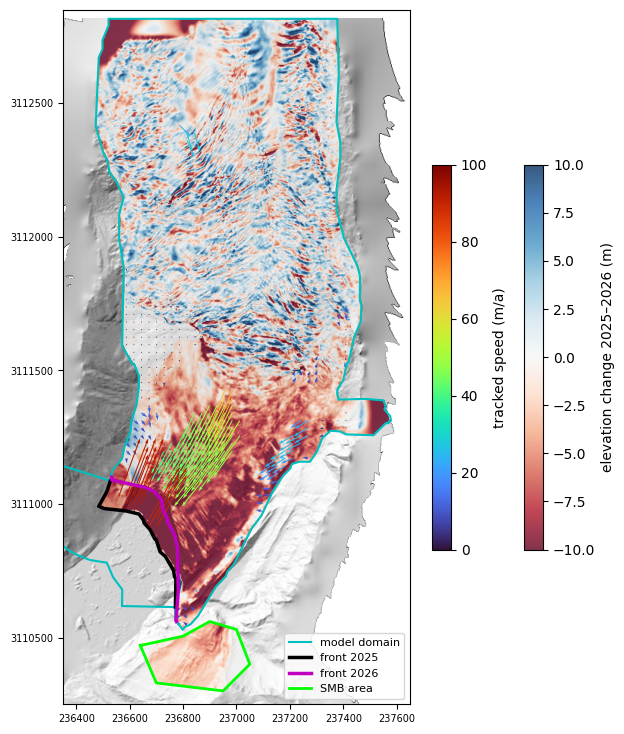

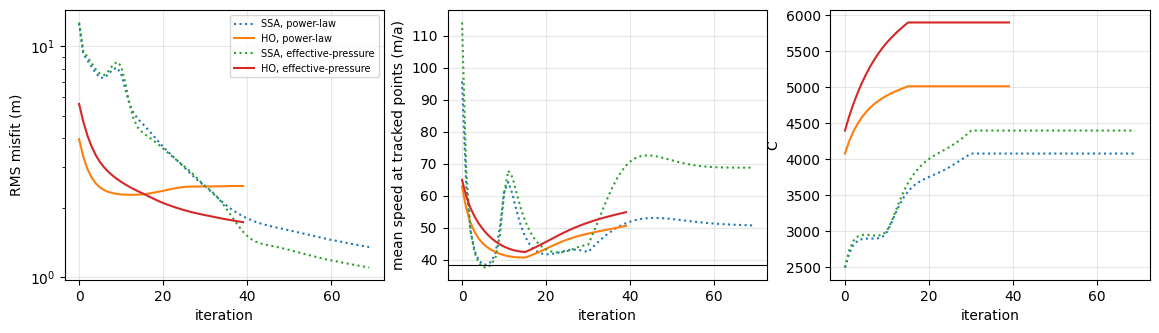

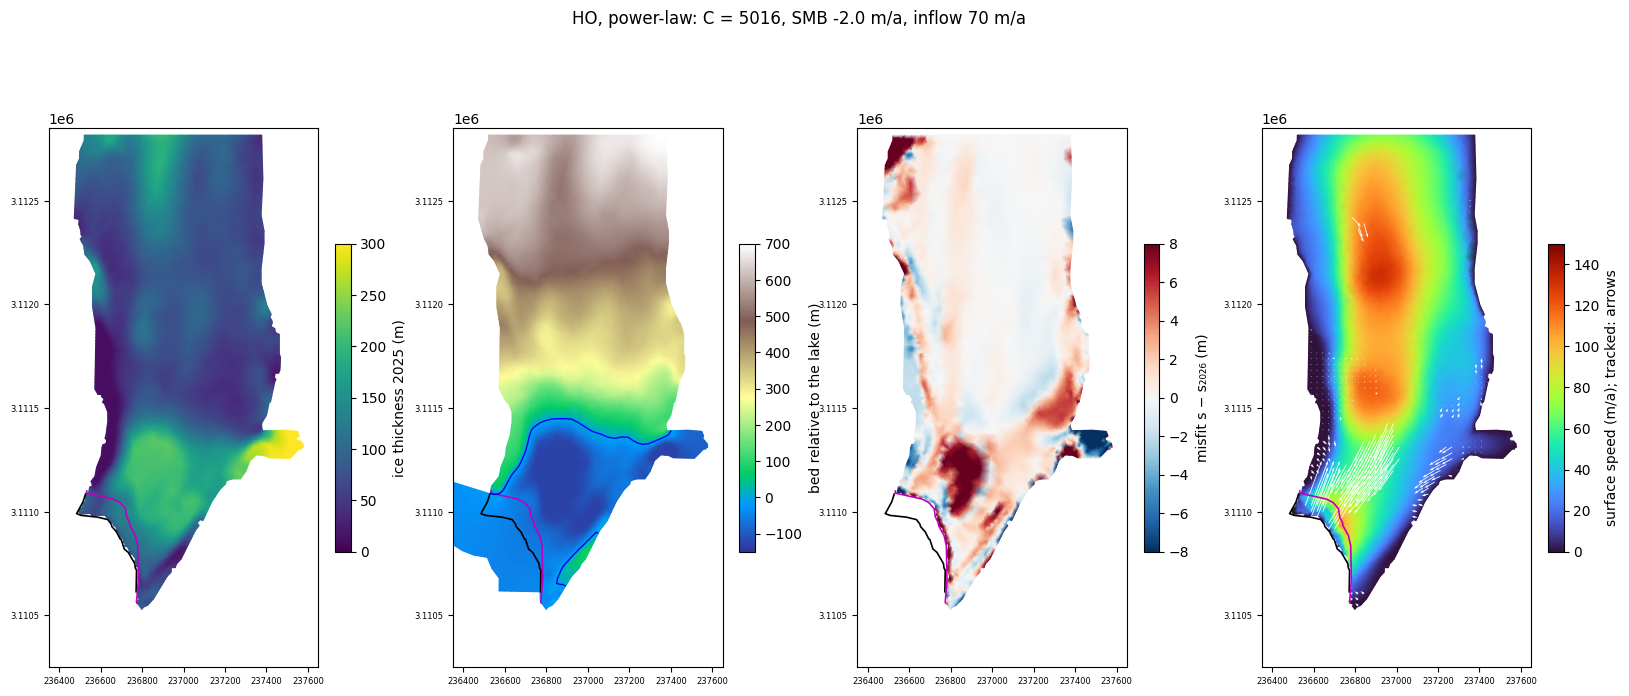

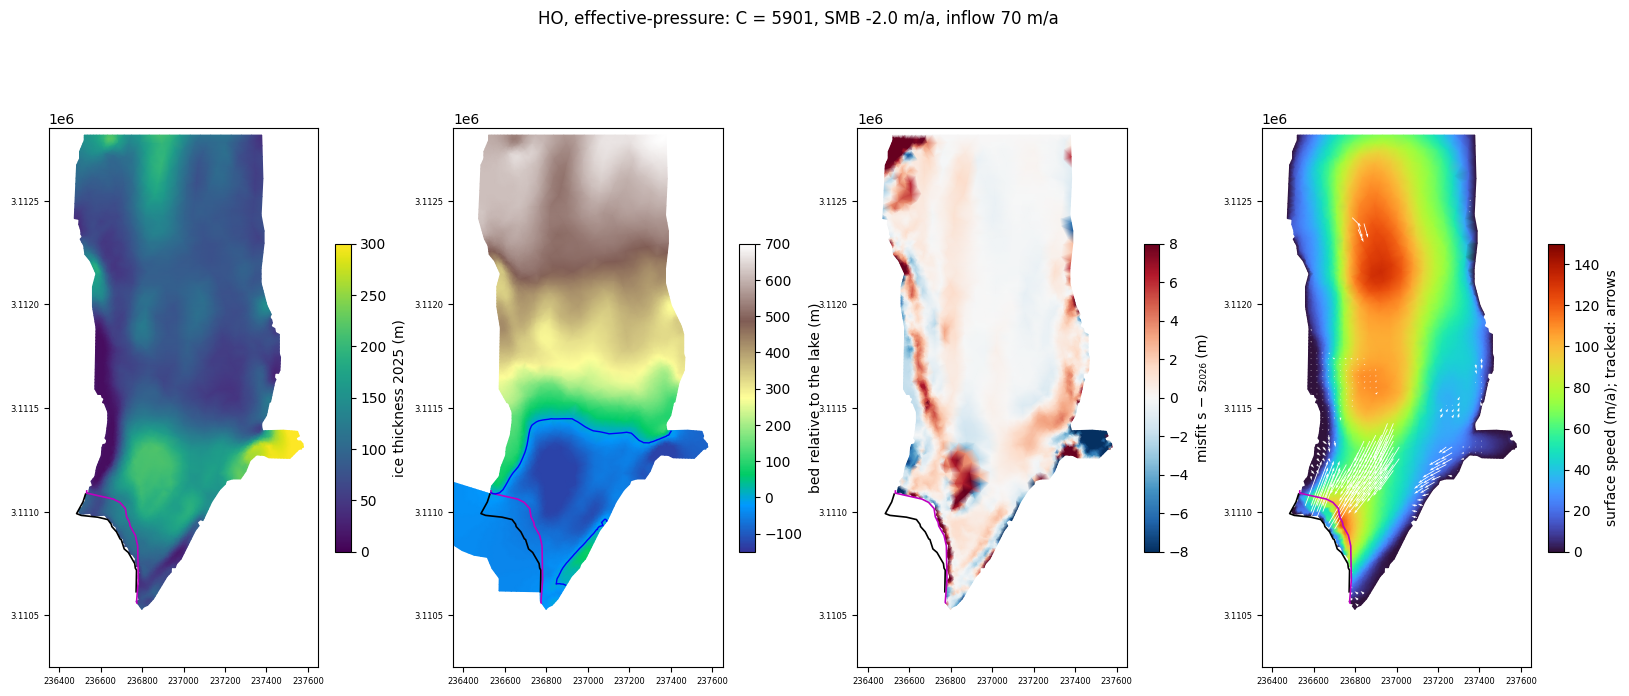

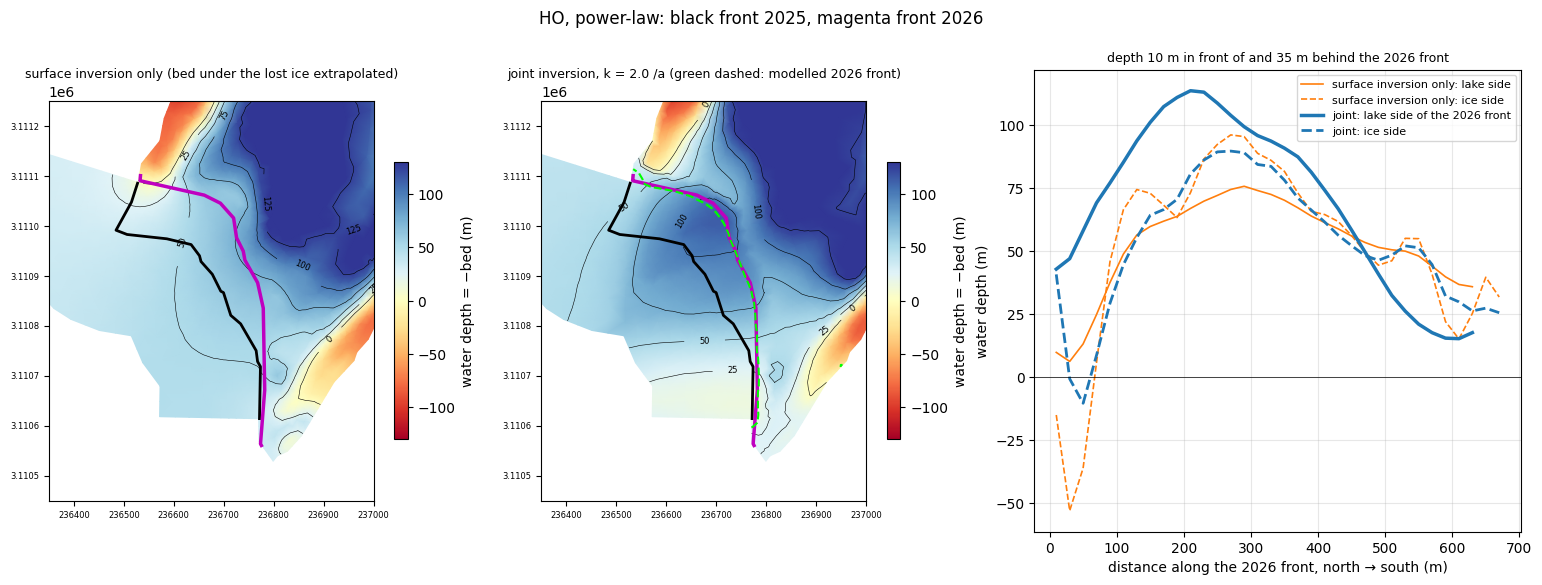

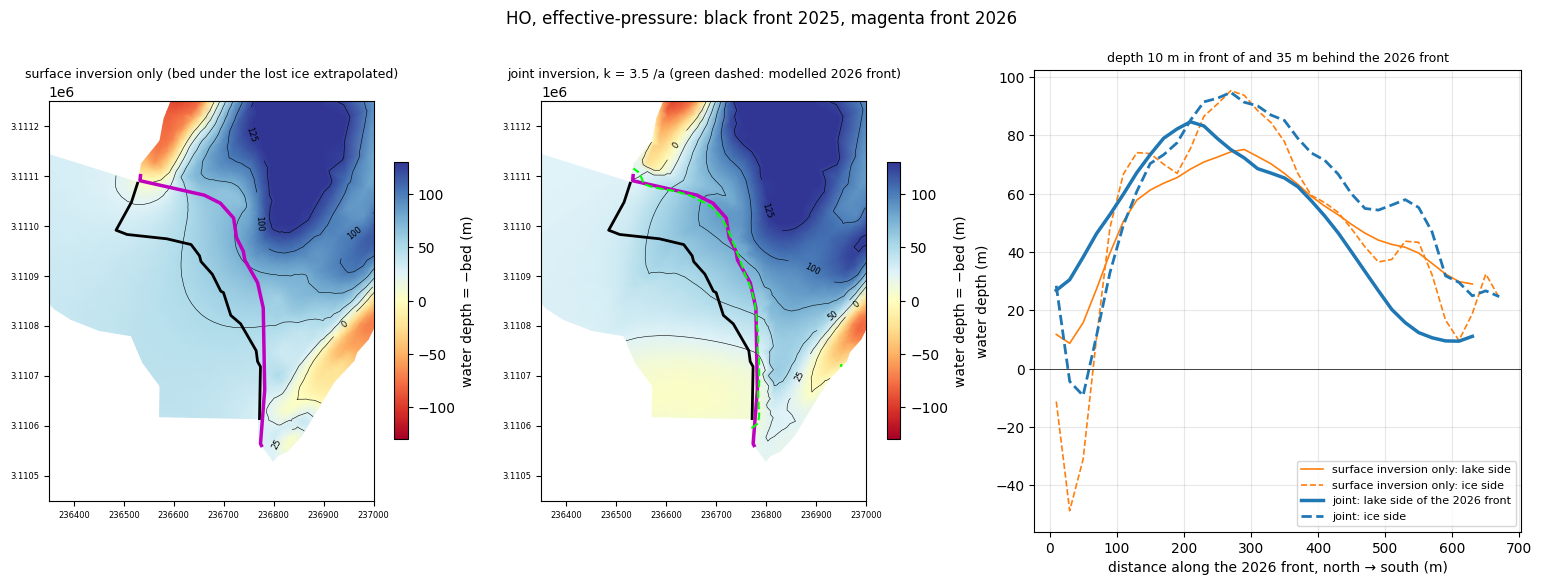

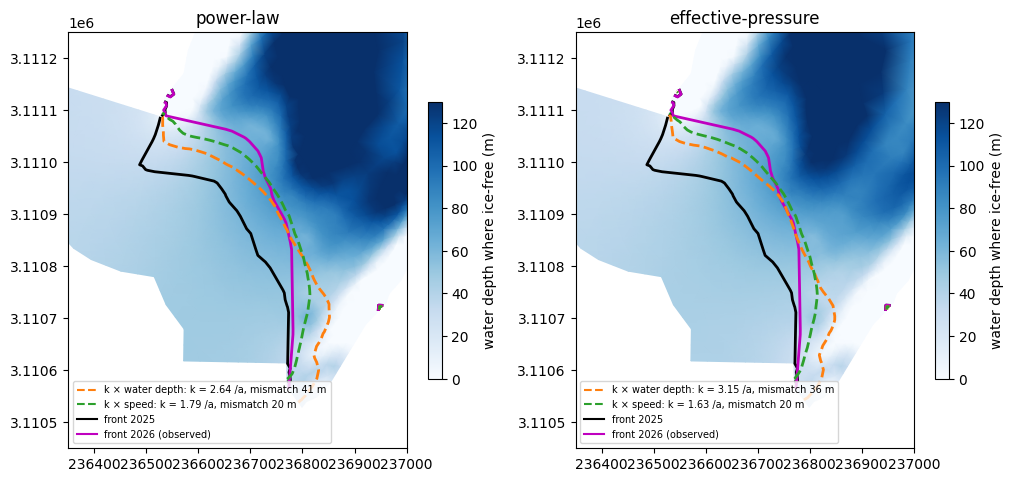

In [13]:
def save_figure(fig, name):
    for extension in ['pdf', 'png']:
        fig.savefig(f'{name}.{extension}', dpi = 200, bbox_inches = 'tight')

T = d.transform
relief = LightSource(315, 45).hillshade(np.where(np.isfinite(d.z26), d.z26, np.nanmean(d.z26)), dx = T.a, dy = -T.e)
extent = (d.X.min(), d.X.max(), d.Y.min(), d.Y.max())
view = dict(xlim = (236350, 237650), ylim = (3110250, 3112850))

#data
fig, ax = plt.subplots(figsize = (7, 10))
ax.imshow(np.ma.masked_where(~np.isfinite(d.z26), relief), cmap = 'gray', extent = extent)
im = ax.imshow(np.where(d.c25 | contains_xy(SMB_AREA, d.X, d.Y), dh, np.nan), cmap = 'RdBu', vmin = -10, vmax = 10, extent = extent, alpha = .8)
fig.colorbar(im, ax = ax, shrink = .5, label = 'elevation change 2025–2026 (m)')
ax.plot(*d.domain.exterior.xy, color = 'c', lw = 1.5, label = 'model domain')
ax.plot(*d.front25.xy, 'k', lw = 2.5, label = 'front 2025'); ax.plot(*d.front26.xy, 'm', lw = 2.5, label = 'front 2026')
ax.plot(*SMB_AREA.exterior.xy, color = 'lime', lw = 2, label = 'SMB area')
q = ax.quiver(tracked.x, tracked.y, tracked.vx, tracked.vy, np.hypot(tracked.vx, tracked.vy), cmap = 'turbo', clim = (0, 100),
              angles = 'xy', scale_units = 'xy', scale = 0.4, width = 0.003)
fig.colorbar(q, ax = ax, shrink = .5, label = 'tracked speed (m/a)')
ax.set(**view); ax.set_aspect('equal'); ax.legend(loc = 'lower right', fontsize = 8); ax.ticklabel_format(style = 'plain'); ax.tick_params(labelsize = 7)
save_figure(fig, 'luggye_data'); plt.show()

#convergence
fig, axs = plt.subplots(1, 3, figsize = (14, 3.5))
for (stage_name, sliding_law), inv in inversions.items():
    hist = inv.state['history']
    style = dict(label = f'{stage_name}, {sliding_law}', ls = '-' if stage_name == stages[-1]['name'] else ':')
    axs[0].plot([h['rms'] for h in hist], **style); axs[1].plot([h['track_model'] for h in hist], **style); axs[2].plot([h['C'] for h in hist], **style)
axs[1].axhline(inv.state['history'][-1]['track_obs'], color = 'k', lw = .8)
for ax, label in zip(axs, ['RMS misfit (m)', 'mean speed at tracked points (m/a)', 'C']):
    ax.set_xlabel('iteration'); ax.set_ylabel(label); ax.grid(alpha = .3)
axs[0].set_yscale('log'); axs[0].legend(fontsize = 7)
save_figure(fig, 'luggye_convergence'); plt.show()

#the inverted glacier
for sliding_law in sliding_laws:
    inv = inversions[(final_stage, sliding_law)]; f, st = inv.f, inv.state
    bed = st['last_bed_used']; H = f.s25 - bed
    fig, axs = plt.subplots(1, 4, figsize = (20, 8))
    def show(ax, field, mask, label, **kw):
        t = Triangulation(f.x, f.y, f.elements, mask = ~np.all(mask[f.elements], axis = 1))
        im = ax.tripcolor(t, field, shading = 'gouraud', **kw); fig.colorbar(im, ax = ax, shrink = .5, label = label)
        ax.plot(*d.front25.xy, 'k', lw = 1.2); ax.plot(*d.front26.xy, 'm', lw = 1.2)
        ax.set(**view); ax.set_aspect('equal'); ax.tick_params(labelsize = 6)
    show(axs[0], H, f.ice25, 'ice thickness 2025 (m)', cmap = 'viridis', vmin = 0, vmax = 300)
    show(axs[1], bed, np.ones(f.x.size, bool), 'bed relative to the lake (m)', cmap = 'terrain', vmin = -150, vmax = 700)
    axs[1].tricontour(inv.tri, bed, levels = [0], colors = 'b', linewidths = 1)
    show(axs[2], st['last_misfit'], f.ice25 & f.ice26, 'misfit s − s₂₀₂₆ (m)', cmap = 'RdBu_r', vmin = -8, vmax = 8)
    show(axs[3], st['last_run_speed'], f.ice25, 'surface speed (m/a); tracked: arrows', cmap = 'turbo', vmin = 0, vmax = 150)
    axs[3].quiver(tracked.x, tracked.y, tracked.vx, tracked.vy, color = 'w', angles = 'xy', scale_units = 'xy', scale = 0.4, width = 0.003)
    fig.suptitle(f'{final_stage}, {sliding_law}: C = {st["C"]:.0f}, SMB {smb} m/a, inflow {u_in:.0f} m/a')
    save_figure(fig, f'luggye_bed_{sliding_law}'); plt.show()

#the joint inversion: the bed near the front before and after, the modelled front, and the depth either side of the 2026 front
for sliding_law in sliding_laws:
    J = joint[sliding_law]; inv = J.inv; f = inv.f
    fig, axs = plt.subplots(1, 3, figsize = (19, 6), gridspec_kw = dict(width_ratios = [1, 1, 1.2]))
    for ax, bed, title, front in [(axs[0], J.bed_start, 'surface inversion only (bed under the lost ice extrapolated)', None),
                                  (axs[1], J.front.bed, f'joint inversion, k = {J.k:.1f} /a (green dashed: modelled 2026 front)', J.front.levelset)]:
        im = ax.tripcolor(inv.tri, -bed, shading = 'gouraud', cmap = 'RdYlBu', vmin = -130, vmax = 130, rasterized = True)
        fig.colorbar(im, ax = ax, shrink = .6, label = 'water depth = −bed (m)')
        cs = ax.tricontour(inv.tri, -bed, levels = [0, 25, 50, 75, 100, 125], colors = 'k', linewidths = .4); ax.clabel(cs, fontsize = 6)
        ax.plot(*d.front25.xy, 'k', lw = 2); ax.plot(*d.front26.xy, 'm', lw = 2.5)
        if front is not None:
            ax.tricontour(inv.tri, front, [0], colors = 'lime', linewidths = 1.5, linestyles = '--')
        ax.set_xlim(236350, 237000); ax.set_ylim(3110450, 3111250); ax.set_aspect('equal'); ax.set_title(title, fontsize = 9); ax.tick_params(labelsize = 6)
    before = J.R.step_across_front(J.bed_start)
    axs[2].plot(J.R.S, before[0], 'C1', lw = 1.2, label = 'surface inversion only: lake side'); axs[2].plot(J.R.S, before[1], 'C1--', lw = 1.2, label = 'surface inversion only: ice side')
    axs[2].plot(J.R.S, J.out, 'C0', lw = 2.5, label = 'joint: lake side of the 2026 front'); axs[2].plot(J.R.S, J.inn, 'C0--', lw = 2, label = 'joint: ice side')
    axs[2].axhline(0, color = 'k', lw = .5); axs[2].set_xlabel('distance along the 2026 front, north → south (m)'); axs[2].set_ylabel('water depth (m)')
    axs[2].legend(fontsize = 8); axs[2].grid(alpha = .3); axs[2].set_title('depth 10 m in front of and 35 m behind the 2026 front', fontsize = 9)
    fig.suptitle(f'{final_stage}, {sliding_law}: black front 2025, magenta front 2026')
    save_figure(fig, f'luggye_joint_{sliding_law}'); plt.show()

#fronts of the calibrated rate laws
fig, axs = plt.subplots(1, len(sliding_laws), figsize = (6*len(sliding_laws), 6), squeeze = False)
for ax, sliding_law in zip(axs[0], sliding_laws):
    inv = inversions[(final_stage, sliding_law)]; f = inv.f
    im = ax.tripcolor(inv.tri, np.maximum(-inv.state['bed'], 0), shading = 'gouraud', cmap = 'Blues', vmin = 0, vmax = 130)
    ax.tricontour(inv.tri, f.φ25, [0], colors = 'k', linewidths = 2); ax.tricontour(inv.tri, f.φ26, [0], colors = 'm', linewidths = 2)
    for law, color in zip(calving_laws, ['tab:orange', 'tab:green']):
        c = calibrations[(sliding_law, law)]
        ax.tricontour(inv.tri, c.run.levelset, [0], colors = color, linewidths = 2, linestyles = '--')
        ax.plot([], [], color = color, ls = '--', label = f'k × {"water depth" if law == "depth" else "speed"}: k = {c.k:.2f} /a, mismatch {c.mismatch:.0f} m')
    ax.plot([], [], 'k', label = 'front 2025'); ax.plot([], [], 'm', label = 'front 2026 (observed)')
    fig.colorbar(im, ax = ax, shrink = .6, label = 'water depth where ice-free (m)')
    ax.set_xlim(236350, 237000); ax.set_ylim(3110450, 3111250); ax.set_aspect('equal'); ax.legend(loc = 'lower left', fontsize = 7); ax.set_title(sliding_law)
save_figure(fig, 'luggye_fronts'); plt.show()

# The beds as GeoTIFFs

For each sliding law, on a 10 m grid in UTM 46N (NaN outside the domain): the bed (m above sea level) and the 2025 ice thickness from the surface inversion alone (`bed`, `thickness2025`; under the ice lost to calving and in the lake this bed is an extrapolation, not data), and from the joint inversion (`bed_joint`, `thickness2025_joint`; under the lost ice this bed is set by the retreat and the rate law).

In [14]:
res = 10.
xs = np.arange(d.domain.bounds[0], d.domain.bounds[2], res) + res/2
ys = np.arange(d.domain.bounds[3], d.domain.bounds[1], -res) - res/2
GX, GY = np.meshgrid(xs, ys)
transform = rasterio.transform.from_origin(xs[0] - res/2, ys[0] + res/2, res, res)
for sliding_law in sliding_laws:
    inv = inversions[(final_stage, sliding_law)]
    bed = inv.state['last_bed_used']
    bed_joint = joint[sliding_law].front.bed
    for name, field in [('bed', bed + lake_level), ('thickness2025', np.where(inv.f.ice25, inv.f.s25 - bed, 0.)),
                        ('bed_joint', bed_joint + lake_level), ('thickness2025_joint', np.where(inv.f.ice25, inv.f.s25 - bed_joint, 0.))]:
        grid = LinearTriInterpolator(inv.tri, field)(GX, GY).filled(np.nan).astype('float32')
        with rasterio.open(f'luggye_{name}_{final_stage}_{sliding_law}.tif', 'w', driver = 'GTiff', width = xs.size, height = ys.size, count = 1,
                           dtype = 'float32', crs = d.crs, transform = transform, nodata = np.nan) as out:
            out.write(grid, 1)
        print(f'wrote luggye_{name}_{final_stage}_{sliding_law}.tif')

wrote luggye_bed_HO_power-law.tif
wrote luggye_thickness2025_HO_power-law.tif
wrote luggye_bed_joint_HO_power-law.tif
wrote luggye_thickness2025_joint_HO_power-law.tif
wrote luggye_bed_HO_effective-pressure.tif
wrote luggye_thickness2025_HO_effective-pressure.tif
wrote luggye_bed_joint_HO_effective-pressure.tif
wrote luggye_thickness2025_joint_HO_effective-pressure.tif


# Notes on the method

**Surface mass balance.** The proxy is Area 2, the slope just south of the terminus, which lowered by a median of 2.95 m in the year without flow. As a single value over the domain, −2.95 m/a starves the upper glacier: at 4900–5250 m the observed surface barely changed, so the model needs ice flowing in to make up for 3 m/a of melt there, and where it cannot (the western icefall) the inverted ice thins to the minimum thickness (a third of the area where the misfit counts, after 70 SSA iterations). Less negative values fit the surface better, and keep the upper glacier thick enough, but need more thinning by flow on the tongue, so the modelled speeds there exceed the tracked ones. In SSA with the power law (70 iterations, $C$ frozen after 30): −2.95 m/a gave an RMS misfit of 1.8 m with the speed at the tracked points 42 m/a (observed 39), 33% at the minimum thickness and the front in 36 m of water; −2.5 m/a: 1.4 m, 47 m/a, 23%, 45 m; −2.0 m/a: 1.1 m, 51 m/a, 13%, 55 m. −2.0 m/a is the default here, the best compromise with a single value; a mass balance that becomes less negative with height would remove the tension.

**Inflow.** The ice enters across the whole top edge of the DEM, at `u_in` in the middle falling to zero at the ends (a parabola), along the inward normal, with its thickness following the observed surfaces; the bed there is the harmonic extension of the inverted bed, so the inversion sets the inflow thickness (as at the top of the JGR flowline). Restricting the inflow to the JGR notebook's channel (`inflow_x = (236800., 237330.)`, with the flat bench west of it closed) leaves the whole western icefall without ice, which then thins to the minimum. Matching the inflow to the model's own speed just inside the edge was unstable (the speed there follows the prescribed inflow), so `u_in` is fixed; 70 m/a over the whole edge carries about what the first, self-consistent runs settled on, and is consistent with the few vectors tracked in the icefall (100–170 m/a further down).

**Excluded from the misfit.** The top-left corner of the glacier lowered by 15 m in the year at 5220 m (`ANOMALY`), which is neither melt nor plausible flow; it is left out of the misfit. So is the small tributary notch on the east edge (`NOTCH`): its edge is closed, so ice there can only thin by melt, and the inversion deepened the bed without limit (to 340 m of ice), as the JGR notebook found; its bed follows its neighbours. Also left out: 25 m around the 2026 front (the smoothed DEM blurs the cliff), the inflow and the sides.

**Bed bounds.** Near the front the model could not thin the ice as fast as observed (up to 8 m/a within 100 m of the 2026 front), and the bed ran away: deeper, until the ice floated, after which a deeper bed means thicker floating ice and a higher surface, so it ran away faster. The bed is therefore no deeper than `bed_min` = −130 m relative to the lake (the lake is 50 m deep on average and 126 m at its deepest; Tsutaki et al., 2019), and the bed correction is limited to 20 m per iteration.

**Friction.** $C$ is calibrated against the tracked speeds rather than taken from the JGR notebook. It ends at about 3850–4900 in ISSM's convention, $C^2$ of 0.05–0.08 MPa (m/a)$^{-1/3}$, a little below the JGR notebook's 0.1 (in SSA, 3849 with the power law and 4122 with effective pressure). Calibrated throughout, $C$ drifts slowly upward while the bed compensates; it is frozen after `C_iterations`, after which the bed fits the surface better but the speeds rise above the tracked ones (the tension of the SMB above).

**Lake level.** The 2026 DEM's lake surface is at 4477.6 m (tight); the 2025 one scatters between 4478 and 4481 m (water surfaces are poor in photogrammetry). The lake is at 4478 m in both years.

**MUMPS.** The development workspace used Debian's PETSc and MUMPS, whose MUMPS cannot order matrices in parallel (ISSM asks for ICNTL 28/29 = 2), and the solves returned NaN. `serial_ordering` removes those two options; on Snellius it changes nothing of substance.

**Development runs.** The defaults come from runs on the 2100-vertex mesh. SSA, 70 iterations from the plastic first guess ($C$ frozen after 30): RMS misfit 1.09 m for both sliding laws, water depth at the 2026 front 55 m (power law) and 35 m (effective pressure). HO with 5 layers from the SSA beds, 31–32 iterations ($C$ recalibrated for 15, then frozen): RMS misfit 2.19 m (power law, still a +8 m patch on the tongue, where 1.5% of the bed sits at `bed_min`) and 1.65 m (effective pressure, still falling); speed at the tracked points 49 and 51 m/a (observed 39); front in 47 and 41 m of water; the ice on the tongue 150–250 m thick over an overdeepening down to 85–130 m below the lake, the upper glacier 50–150 m. On these HO beds, the speed law calibrated (6 steps in the year) to k = 2.09 /a (power law) and 1.91 /a (effective pressure), with mismatches of the front of 42 and 43 m.

**Joint inversion.** Developed in SSA with the power law on the 2100-vertex mesh. *Why*: on the surface-inverted bed, calving at $k$ × depth (calibrated to the lost area) left a front mismatch of about 60 m, because the bed under the lost ice was only an extrapolation; yet the calving rate the retreat demands (retreat rate plus ice speed normal to the front) falls smoothly from about 185 m/a in the north to about 25 m/a in the south, as a bed shoaling southward would give. *Front rule alone* (8 cycles, $k$ = 2.0 /a): surface RMS 0.99 m and front mismatch 1.1 m, but the bed stepped by 37 m RMS across the 2026 front, because nothing tied the two parts together and the bed within about 100 m behind the front is weakly constrained by the surface (it varied by 25 m between runs with the same fit). *With the smoothness rule* (8 more cycles): surface RMS 1.22 m, front mismatch 4.2 m, and the depths either side of the 2026 front agree within about 10 m along its southern two-thirds (for example 90 against 84 m in the middle, 26 against 27 m near the south end). In the northern 200 m the lake side stays deeper (45–105 m) than the ice side (above lake level to 75 m): there the bed behind the front climbs towards the steep west wall of the valley. *The choice of $k$*: the retreat only fixes $k$ × depth, so a larger $k$ gives a shallower strip. $k$ = 2.0 /a gave the smoothest join; 2.2 /a was nearly as good (surface 1.28 m, front 3.9 m); with 2.5 /a the strip came out shallower than the bed behind it and the run was unstable (once the modelled front passes the observed one it meets the deeper water behind it and keeps retreating). *Uniqueness*: for a given $k$, restarting with the strip 40 m shallower or 60 m deeper gave the same strip depths within about 5 m. *Caveats*: with one depth per retreat path free, the depth law can fit almost any retreat pattern, so the fit does not test the law; soundings in the newly ice-free water, or the next mapped front, would. *HO check* (5 layers, 2100-vertex mesh, from the HO surface-inverted beds; about 40 minutes per cycle on one core): with the power law and $k$ = 2.0 /a, after 6 cycles the surface RMS is 1.85 m (2.19 m before), the front mismatch 3.4 m, and the two sides of the 2026 front agree within 10–25 m over its middle. With effective pressure, $k$ = 2.0 /a left the lost-ice bed 40–70 m deeper than the bed behind the front: this sliding law makes the ice near the front faster over a shallower bed, so it needs more calving per metre of water (as the area calibration on the surface-inverted bed already showed: 5.1 against 2.8 /a). With $k$ = 3.5 /a, after 8 cycles (3 at 2.0, then 8 at 3.5): surface RMS 1.19 m (1.65 m before), front mismatch 3.7 m, and over the middle 300 m of the front the lake side and the ice side agree within 10 m RMS (64 against 70 m), against 24 m RMS for the power law (92 against 71 m). Speeds at the tracked points: 54 m/a (power law) and 60 m/a (effective pressure), against 39 m/a observed. With the notch excluded, the thickest ice is 220 m. In both, the north end keeps a steep rise towards the west wall, and the strip in the south comes out 10–25 m shallower than the bed behind it.

**Rate laws.** Calving at $k$ times the water depth retreats the front about evenly along its length (slightly more where the bed under the lost ice, which only the harmonic extension sets, is deeper), while the observed front retreated about 100 m at its northern end and not at all at its southern end. The northern end is where the ice is fastest (80–90 m/a tracked), so calving at $k$ times the ice speed follows the observed retreat more closely (in SSA, the mismatch of the front fell from 62 to 43 m with the power law, k = 2.82 /a for depth and 1.97 /a for speed, and from 66 to 46 m with effective pressure, k = 5.14 and 1.74 /a, against a mean retreat of 57 m). Both laws still retreat the middle and the south of the front by 30–40 m more than observed (it barely moved there).